In [1]:

# Step 1: Import libraries and load the Fashion-MNIST dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import fashion_mnist

# Display library versions
print("ENVIRONMENT INFORMATION")
print("------------------------")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("TensorFlow version:", tf.__version__)

# Load the Fashion-MNIST dataset
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Define the ten clothing categories
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Display initial dataset information
print("\nDATASET LOADED SUCCESSFULLY")
print("---------------------------")
print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])
print("Training image dimensions:", X_train.shape[1:])
print("Testing image dimensions:", X_test.shape[1:])
print("Number of classes:", len(class_names))
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

ENVIRONMENT INFORMATION
------------------------
NumPy version: 2.3.5
Pandas version: 2.3.3
TensorFlow version: 2.21.0

DATASET LOADED SUCCESSFULLY
---------------------------
Training images: 60000
Testing images: 10000
Training image dimensions: (28, 28)
Testing image dimensions: (28, 28)
Number of classes: 10
Training labels: (60000,)
Testing labels: (10000,)


In [2]:

# Step 2: Inspect the structure and quality of Fashion-MNIST

print("DATASET STRUCTURE AND QUALITY ANALYSIS")
print("--------------------------------------")

# 1. Inspect array data types
print("\n1. DATA TYPES")
print("Training images:", X_train.dtype)
print("Training labels:", y_train.dtype)
print("Testing images:", X_test.dtype)
print("Testing labels:", y_test.dtype)

# 2. Inspect pixel intensity values
print("\n2. PIXEL INTENSITY DISTRIBUTION")
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())
print("Mean pixel value:", round(X_train.mean(), 2))
print("Standard deviation:", round(X_train.std(), 2))

# 3. Check for missing or invalid values
print("\n3. MISSING AND INVALID VALUES")
print("Missing values in training images:", np.isnan(X_train).sum())
print("Missing values in testing images:", np.isnan(X_test).sum())
print("Missing training labels:", pd.isna(y_train).sum())
print("Missing testing labels:", pd.isna(y_test).sum())

# 4. Check label range
print("\n4. LABEL VALIDATION")
print("Unique training labels:", np.unique(y_train))
print("Unique testing labels:", np.unique(y_test))

# 5. Check dataset dimensions and memory usage
print("\n5. DATASET MEMORY USAGE")
print("Training images:", round(X_train.nbytes / (1024 ** 2), 2), "MB")
print("Testing images:", round(X_test.nbytes / (1024 ** 2), 2), "MB")
print("Total image memory:",
      round((X_train.nbytes + X_test.nbytes) / (1024 ** 2), 2), "MB")

DATASET STRUCTURE AND QUALITY ANALYSIS
--------------------------------------

1. DATA TYPES
Training images: uint8
Training labels: uint8
Testing images: uint8
Testing labels: uint8

2. PIXEL INTENSITY DISTRIBUTION
Minimum pixel value: 0
Maximum pixel value: 255
Mean pixel value: 72.94
Standard deviation: 90.02

3. MISSING AND INVALID VALUES
Missing values in training images: 0
Missing values in testing images: 0
Missing training labels: 0
Missing testing labels: 0

4. LABEL VALIDATION
Unique training labels: [0 1 2 3 4 5 6 7 8 9]
Unique testing labels: [0 1 2 3 4 5 6 7 8 9]

5. DATASET MEMORY USAGE
Training images: 44.86 MB
Testing images: 7.48 MB
Total image memory: 52.34 MB


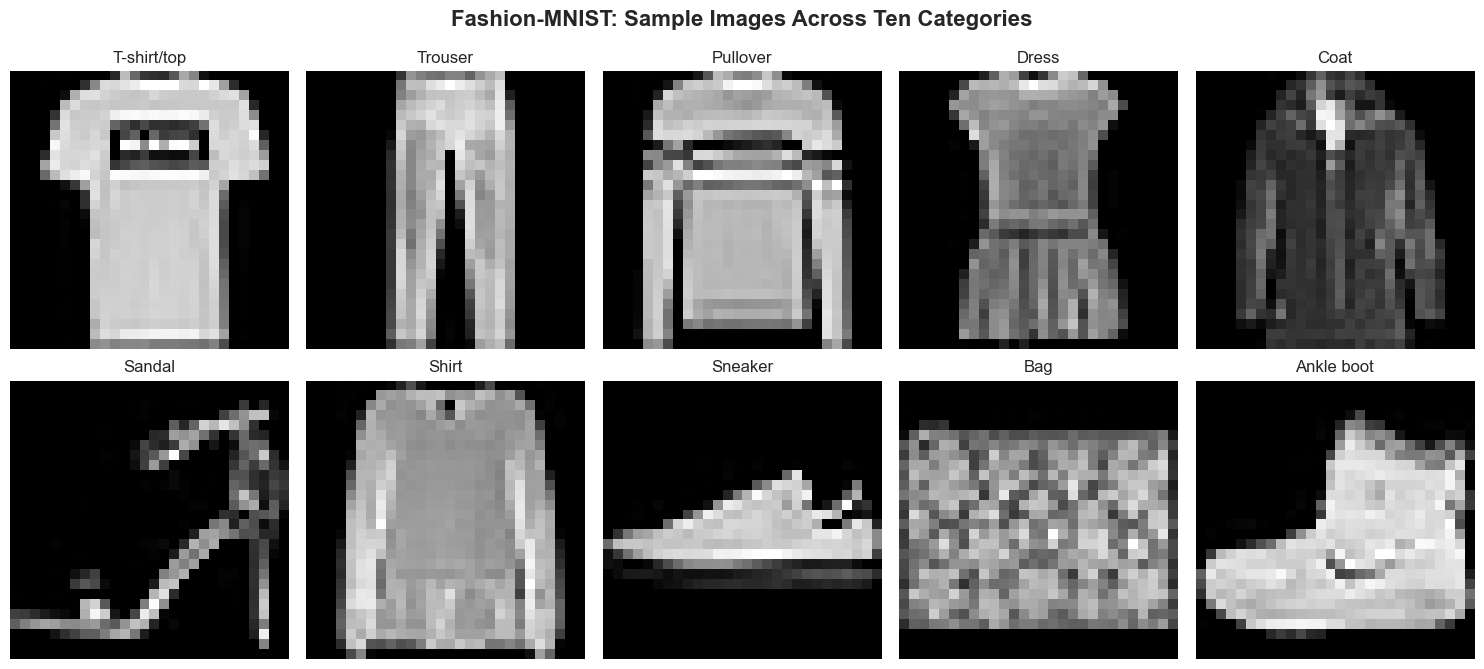

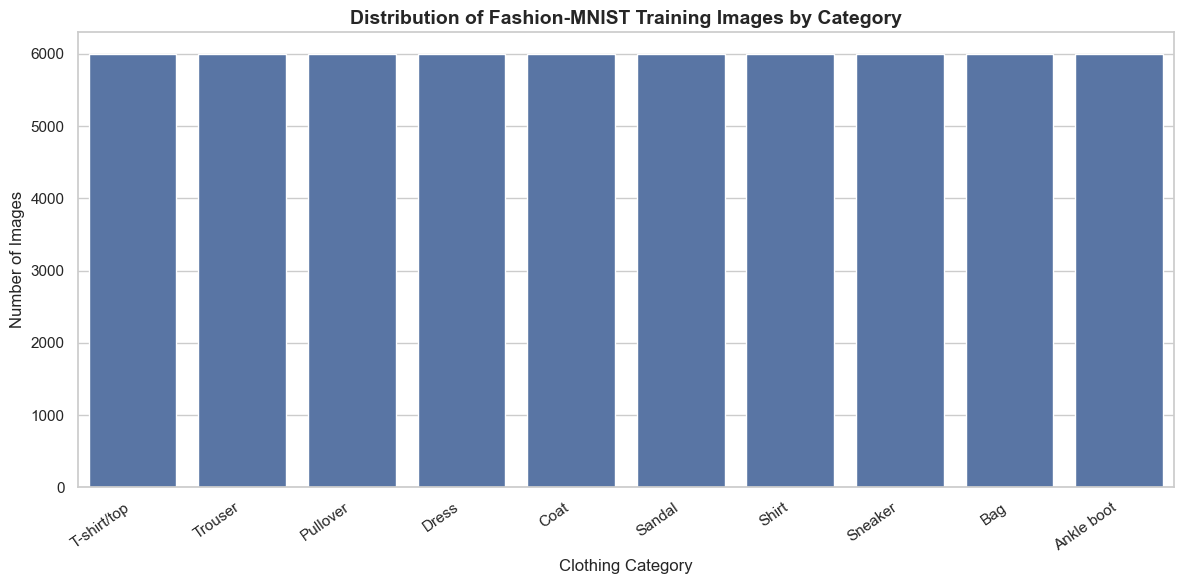

TRAINING CLASS DISTRIBUTION
---------------------------
T-shirt/top: 6,000 images
Trouser: 6,000 images
Pullover: 6,000 images
Dress: 6,000 images
Coat: 6,000 images
Sandal: 6,000 images
Shirt: 6,000 images
Sneaker: 6,000 images
Bag: 6,000 images
Ankle boot: 6,000 images


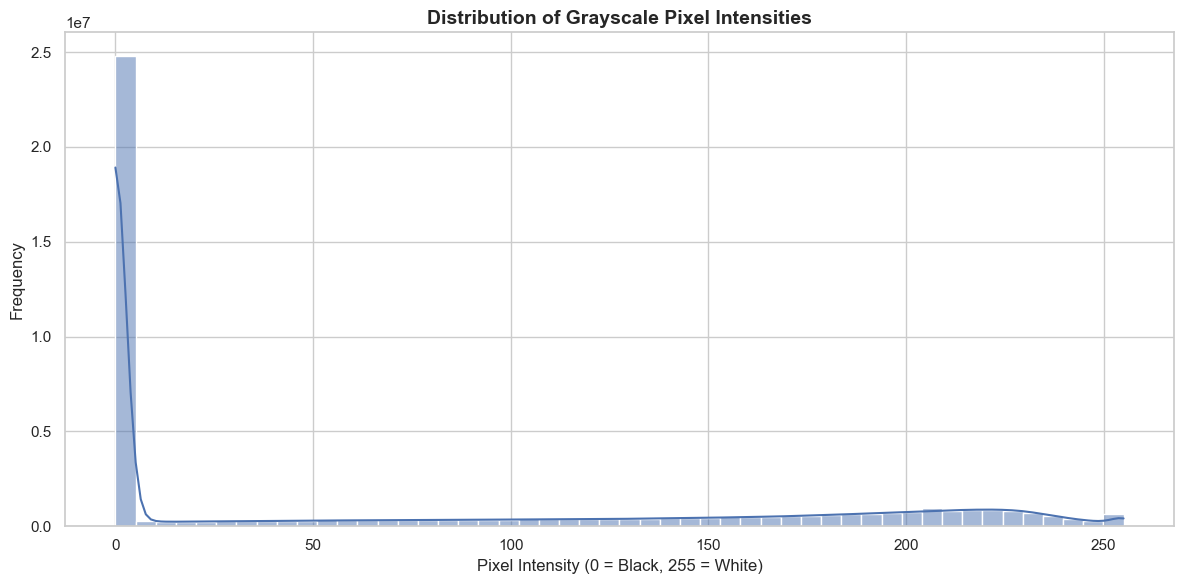

In [3]:

# Step 3: Exploratory Data Analysis (EDA)
# Visual inspection of Fashion-MNIST

# Set a consistent visual style
sns.set_theme(style="whitegrid")

# --------------------------------------------------
# VISUAL 1: Sample images from all ten categories
# --------------------------------------------------

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for class_id, ax in enumerate(axes.flat):
    # Find the first training image belonging to this category
    image_index = np.where(y_train == class_id)[0][0]

    # Display the image
    ax.imshow(X_train[image_index], cmap="gray")
    ax.set_title(class_names[class_id])
    ax.axis("off")

fig.suptitle(
    "Fashion-MNIST: Sample Images Across Ten Categories",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# VISUAL 2: Distribution of training images by class
# --------------------------------------------------

class_counts = pd.Series(y_train).value_counts().sort_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=class_names,
    y=class_counts.values
)

plt.title(
    "Distribution of Fashion-MNIST Training Images by Category",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Clothing Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

print("TRAINING CLASS DISTRIBUTION")
print("---------------------------")

for class_id, count in class_counts.items():
    print(f"{class_names[class_id]}: {count:,} images")


# --------------------------------------------------
# VISUAL 3: Pixel intensity distribution
# --------------------------------------------------

plt.figure(figsize=(12, 6))

sns.histplot(
    X_train.flatten(),
    bins=50,
    kde=True
)

plt.title(
    "Distribution of Grayscale Pixel Intensities",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Pixel Intensity (0 = Black, 255 = White)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

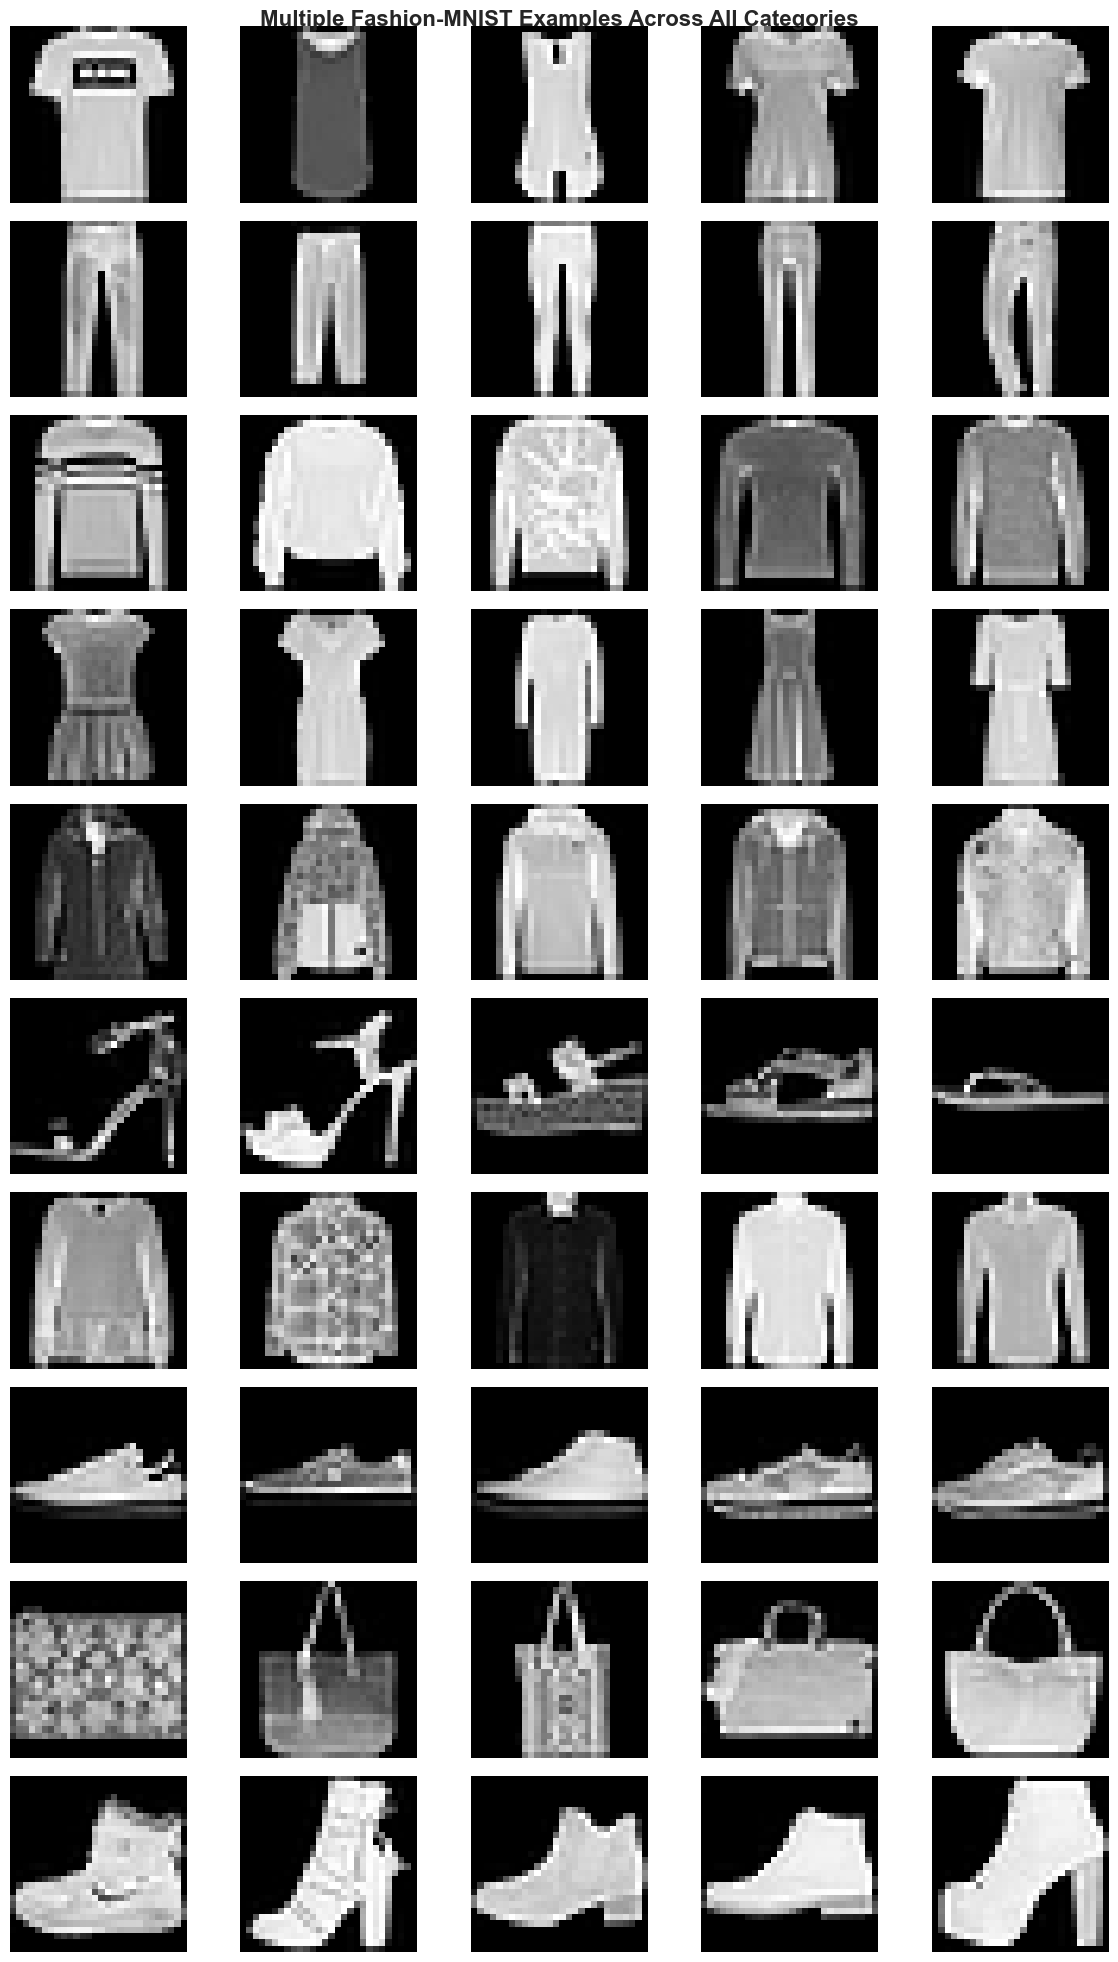

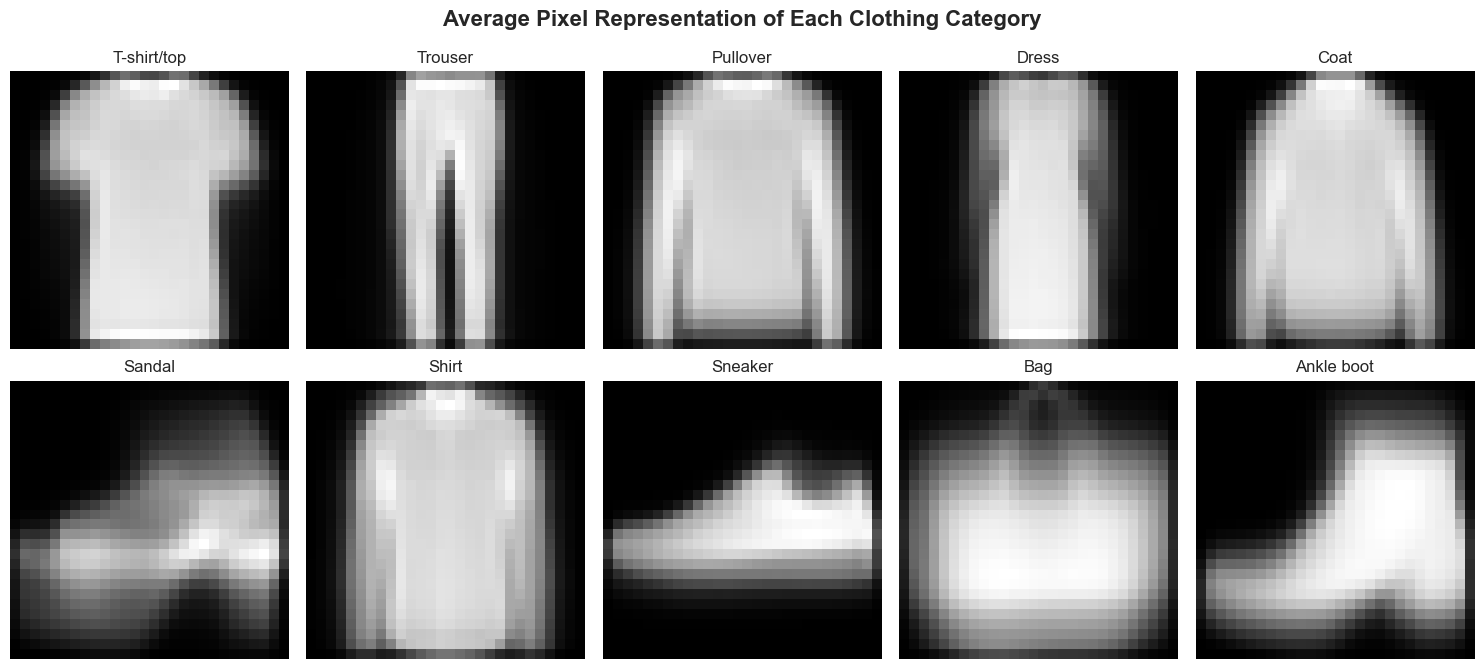

CATEGORY-LEVEL PIXEL INTENSITY STATISTICS
-----------------------------------------
             Mean_Intensity  Std_Intensity  Average_Image_Variation
Category                                                           
T-shirt/top           83.03          28.91                    81.61
Trouser               56.84          14.52                    85.16
Pullover              96.06          32.65                    82.38
Dress                 66.02          21.40                    85.65
Coat                  98.26          26.43                    90.43
Sandal                34.87          15.84                    63.27
Shirt                 84.61          33.08                    76.46
Sneaker               42.76          12.84                    72.66
Bag                   90.16          28.77                    87.23
Ankle boot            76.81          18.30                    91.80


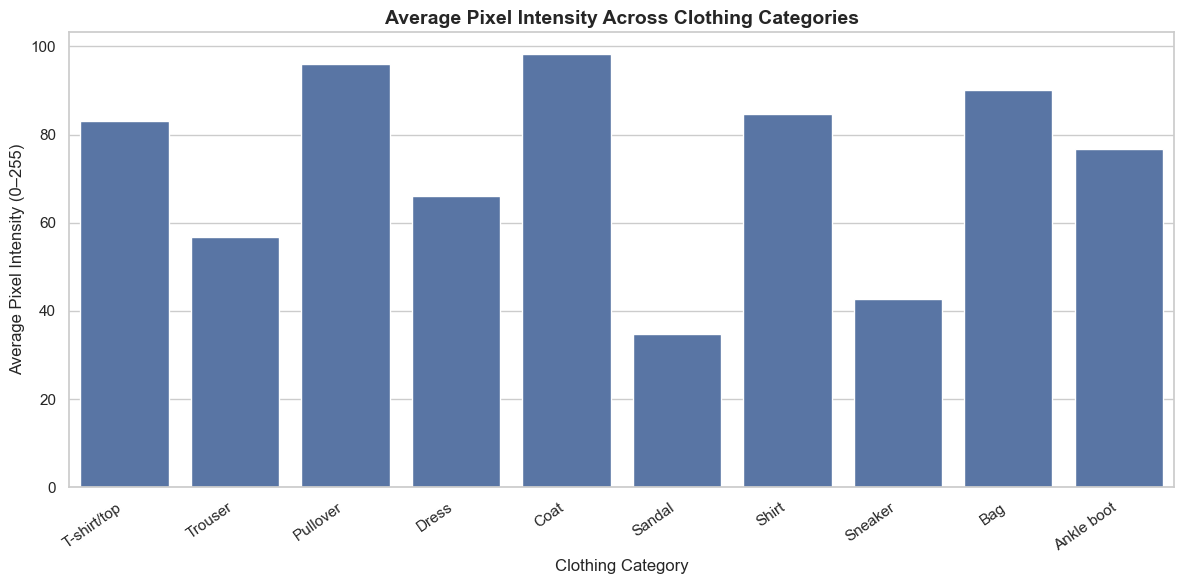

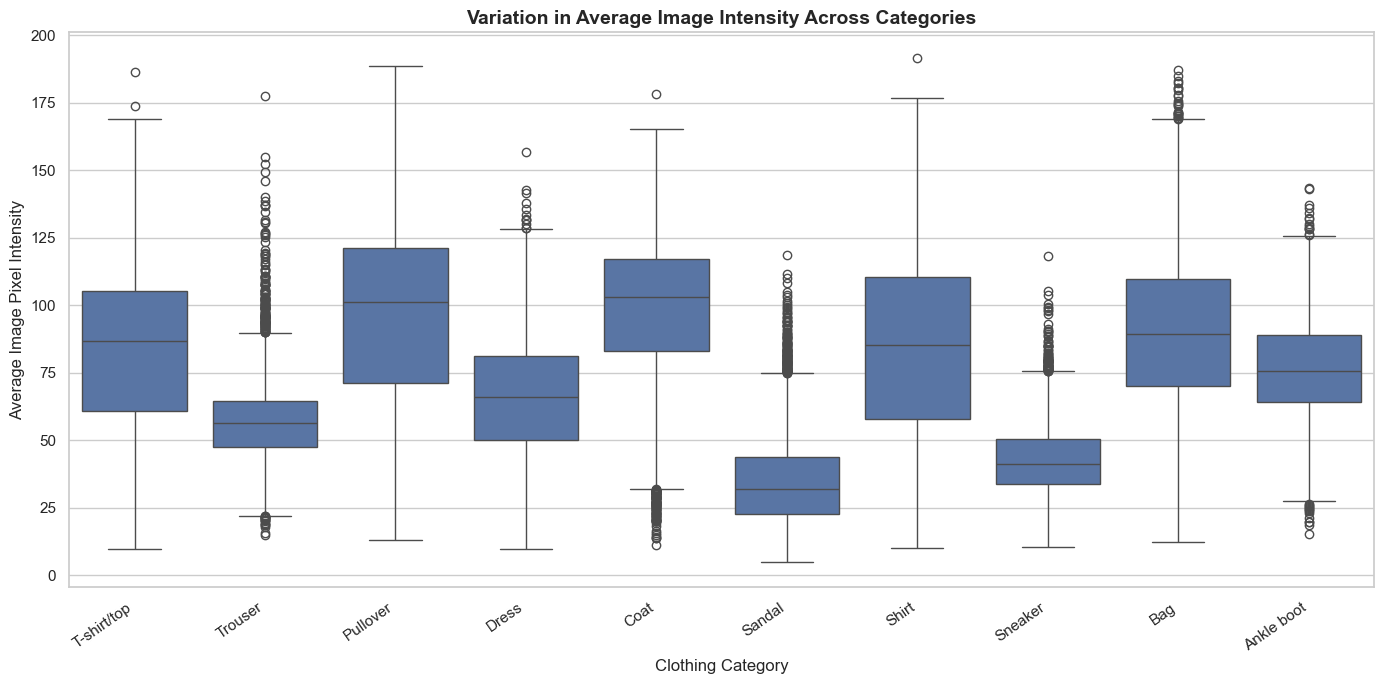

In [4]:

# Step 4: Deeper visual exploration of Fashion-MNIST
# Investigating image variation and category characteristics

# --------------------------------------------------
# VISUAL 4: Multiple image examples per category
# --------------------------------------------------

fig, axes = plt.subplots(10, 5, figsize=(12, 20))

for class_id in range(10):

    # Select five images from the current category
    class_indices = np.where(y_train == class_id)[0][:5]

    for column, image_index in enumerate(class_indices):

        axes[class_id, column].imshow(
            X_train[image_index],
            cmap="gray"
        )

        axes[class_id, column].axis("off")

        if column == 0:
            axes[class_id, column].set_ylabel(
                class_names[class_id],
                fontsize=10
            )

fig.suptitle(
    "Multiple Fashion-MNIST Examples Across All Categories",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# VISUAL 5: Average image for each category
# --------------------------------------------------

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for class_id, ax in enumerate(axes.flat):

    # Select all images belonging to the current category
    class_images = X_train[y_train == class_id]

    # Calculate the average pixel intensity at each position
    average_image = np.mean(class_images, axis=0)

    # Display the average image
    ax.imshow(average_image, cmap="gray")

    ax.set_title(class_names[class_id])
    ax.axis("off")

fig.suptitle(
    "Average Pixel Representation of Each Clothing Category",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# VISUAL 6: Calculate image-level intensity statistics
# --------------------------------------------------

# Calculate the average pixel intensity for every image
image_mean_intensity = X_train.mean(axis=(1, 2))

# Calculate pixel intensity standard deviation for every image
image_std_intensity = X_train.std(axis=(1, 2))

# Create a DataFrame containing the image-level statistics
intensity_data = pd.DataFrame({
    "Category": [class_names[label] for label in y_train],
    "Mean Intensity": image_mean_intensity,
    "Intensity Standard Deviation": image_std_intensity
})

# Calculate category-level summary statistics
category_statistics = intensity_data.groupby("Category").agg(
    Mean_Intensity=("Mean Intensity", "mean"),
    Std_Intensity=("Mean Intensity", "std"),
    Average_Image_Variation=("Intensity Standard Deviation", "mean")
).reindex(class_names)

print("CATEGORY-LEVEL PIXEL INTENSITY STATISTICS")
print("-----------------------------------------")

print(category_statistics.round(2))


# --------------------------------------------------
# VISUAL 7: Average pixel intensity by category
# --------------------------------------------------

plt.figure(figsize=(12, 6))

sns.barplot(
    data=intensity_data,
    x="Category",
    y="Mean Intensity",
    order=class_names,
    errorbar=None
)

plt.title(
    "Average Pixel Intensity Across Clothing Categories",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Clothing Category")
plt.ylabel("Average Pixel Intensity (0–255)")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# VISUAL 8: Distribution of image-level pixel intensity
# --------------------------------------------------

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=intensity_data,
    x="Category",
    y="Mean Intensity",
    order=class_names
)

plt.title(
    "Variation in Average Image Intensity Across Categories",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Clothing Category")
plt.ylabel("Average Image Pixel Intensity")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

In [5]:

# STEP 5: COMPREHENSIVE FASHION-MNIST EDA DIAGNOSTIC REPORT
# Generates numerical findings for detailed academic interpretation.

from sklearn.metrics.pairwise import cosine_similarity

print("=" * 75)
print("COMPREHENSIVE FASHION-MNIST EXPLORATORY DATA ANALYSIS REPORT")
print("=" * 75)


# --------------------------------------------------
# 1. CATEGORY-LEVEL PIXEL INTENSITY STATISTICS
# --------------------------------------------------

print("\n1. CATEGORY-LEVEL PIXEL INTENSITY STATISTICS")
print("-" * 75)

category_results = []

for class_id, class_name in enumerate(class_names):

    images = X_train[y_train == class_id]

    # Calculate image-level mean and standard deviation
    individual_means = images.mean(axis=(1, 2))
    individual_stds = images.std(axis=(1, 2))

    category_results.append({
        "Category": class_name,
        "Images": len(images),
        "Mean Intensity": individual_means.mean(),
        "Intensity Std": individual_means.std(),
        "Average Image Variation": individual_stds.mean(),
        "Minimum Mean": individual_means.min(),
        "Maximum Mean": individual_means.max()
    })

category_df = pd.DataFrame(category_results).set_index("Category")

print(category_df.round(3).to_string())


# --------------------------------------------------
# 2. BRIGHTEST AND DARKEST CATEGORIES
# --------------------------------------------------

print("\n\n2. BRIGHTEST AND DARKEST CATEGORIES")
print("-" * 75)

brightest = category_df["Mean Intensity"].idxmax()
darkest = category_df["Mean Intensity"].idxmin()

print("Brightest category:", brightest)
print("Average intensity:", round(category_df.loc[brightest, "Mean Intensity"], 3))

print("\nDarkest category:", darkest)
print("Average intensity:", round(category_df.loc[darkest, "Mean Intensity"], 3))


# --------------------------------------------------
# 3. CATEGORY VARIATION
# --------------------------------------------------

print("\n\n3. CATEGORY VARIATION")
print("-" * 75)

most_variable = category_df["Average Image Variation"].idxmax()
least_variable = category_df["Average Image Variation"].idxmin()

print("Highest average within-image pixel variation:", most_variable)
print("Value:", round(category_df.loc[most_variable, "Average Image Variation"], 3))

print("\nLowest average within-image pixel variation:", least_variable)
print("Value:", round(category_df.loc[least_variable, "Average Image Variation"], 3))

print("\nVariation in average brightness between images:")

for category in class_names:
    print(
        f"{category}: "
        f"{category_df.loc[category, 'Intensity Std']:.3f}"
    )


# --------------------------------------------------
# 4. OVERALL PIXEL INTENSITY DISTRIBUTION
# --------------------------------------------------

print("\n\n4. OVERALL PIXEL INTENSITY DISTRIBUTION")
print("-" * 75)

pixel_values = X_train.flatten()

print("Minimum:", np.min(pixel_values))
print("Maximum:", np.max(pixel_values))
print("Mean:", round(np.mean(pixel_values), 3))
print("Median:", round(np.median(pixel_values), 3))
print("Standard deviation:", round(np.std(pixel_values), 3))

print("25th percentile:", round(np.percentile(pixel_values, 25), 3))
print("50th percentile:", round(np.percentile(pixel_values, 50), 3))
print("75th percentile:", round(np.percentile(pixel_values, 75), 3))
print("90th percentile:", round(np.percentile(pixel_values, 90), 3))
print("95th percentile:", round(np.percentile(pixel_values, 95), 3))


# --------------------------------------------------
# 5. CATEGORY SIMILARITY USING AVERAGE IMAGES
# --------------------------------------------------

print("\n\n5. CATEGORY SIMILARITY ANALYSIS")
print("-" * 75)

# Generate one average image for each category
average_images = []

for class_id in range(len(class_names)):
    class_images = X_train[y_train == class_id]
    average_images.append(class_images.mean(axis=0).flatten())

average_images = np.array(average_images)

# Calculate cosine similarity between average images
similarity_matrix = cosine_similarity(average_images)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=class_names,
    columns=class_names
)

print("\nCOSINE SIMILARITY MATRIX:")
print(similarity_df.round(3).to_string())

# Find the most similar pair, excluding self-comparisons
similarity_copy = similarity_matrix.copy()
np.fill_diagonal(similarity_copy, -1)

most_similar_index = np.unravel_index(
    np.argmax(similarity_copy),
    similarity_copy.shape
)

print("\nMost similar average-image categories:")
print(class_names[most_similar_index[0]], "and", class_names[most_similar_index[1]])
print("Cosine similarity:", round(similarity_copy[most_similar_index], 4))


# --------------------------------------------------
# 6. IMAGE-LEVEL VARIATION AND OUTLIER SCREENING
# --------------------------------------------------

print("\n\n6. IMAGE-LEVEL VARIATION AND OUTLIER SCREENING")
print("-" * 75)

image_means = X_train.mean(axis=(1, 2))
image_stds = X_train.std(axis=(1, 2))

q1 = np.percentile(image_means, 25)
q3 = np.percentile(image_means, 75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

potential_outliers = np.sum(
    (image_means < lower_bound) |
    (image_means > upper_bound)
)

print("Average image brightness:", round(image_means.mean(), 3))
print("Average within-image standard deviation:", round(image_stds.mean(), 3))
print("Image brightness Q1:", round(q1, 3))
print("Image brightness Q3:", round(q3, 3))
print("Image brightness IQR:", round(iqr, 3))
print("Potential brightness outliers:", int(potential_outliers))


# --------------------------------------------------
# 7. DATASET BALANCE AND COMPLETENESS
# --------------------------------------------------

print("\n\n7. DATASET BALANCE AND COMPLETENESS")
print("-" * 75)

unique, counts = np.unique(y_train, return_counts=True)

print("Total training images:", len(X_train))
print("Total testing images:", len(X_test))
print("Total images:", len(X_train) + len(X_test))
print("Number of categories:", len(unique))
print("Minimum images per category:", counts.min())
print("Maximum images per category:", counts.max())
print("Training class distribution balanced:", counts.min() == counts.max())

print("Training image missing values:", np.isnan(X_train).sum())
print("Testing image missing values:", np.isnan(X_test).sum())

print("Duplicate training images:", len(X_train) - len(np.unique(
    X_train.reshape(len(X_train), -1), axis=0
)))

print("Duplicate testing images:", len(X_test) - len(np.unique(
    X_test.reshape(len(X_test), -1), axis=0
)))


# --------------------------------------------------
# 8. CATEGORY-LEVEL SUMMARY AND AUTOMATIC FINDINGS
# --------------------------------------------------

print("\n\n8. AUTOMATIC EDA FINDINGS")
print("-" * 75)

print("1. All ten categories are represented in the training dataset.")
print("2. The training dataset contains an equal number of images per category.")
print("3. The brightest category is:", brightest)
print("4. The darkest category is:", darkest)
print("5. The highest within-image intensity variation occurs in:", most_variable)
print("6. The lowest within-image intensity variation occurs in:", least_variable)
print("7. The most similar average-image categories are:",
      class_names[most_similar_index[0]], "and",
      class_names[most_similar_index[1]])

print("\nEND OF COMPREHENSIVE EDA REPORT")
print("=" * 75)

COMPREHENSIVE FASHION-MNIST EXPLORATORY DATA ANALYSIS REPORT

1. CATEGORY-LEVEL PIXEL INTENSITY STATISTICS
---------------------------------------------------------------------------
             Images  Mean Intensity  Intensity Std  Average Image Variation  Minimum Mean  Maximum Mean
Category                                                                                               
T-shirt/top    6000          83.030         28.911                   81.609         9.754       186.316
Trouser        6000          56.841         14.523                   85.155        15.129       177.750
Pullover       6000          96.059         32.648                   82.380        13.176       188.710
Dress          6000          66.019         21.395                   85.649         9.835       156.945
Coat           6000          98.258         26.427                   90.432        11.089       178.149
Sandal         6000          34.868         15.835                   63.266         4.944

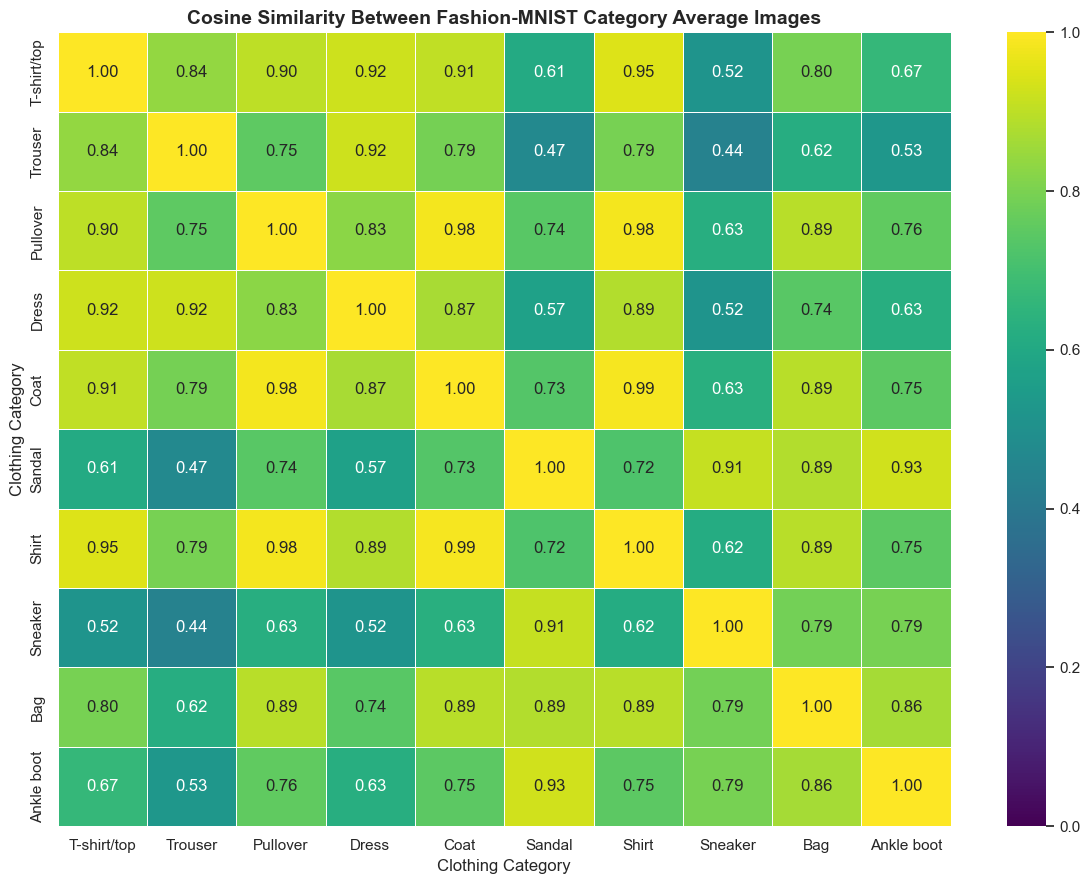

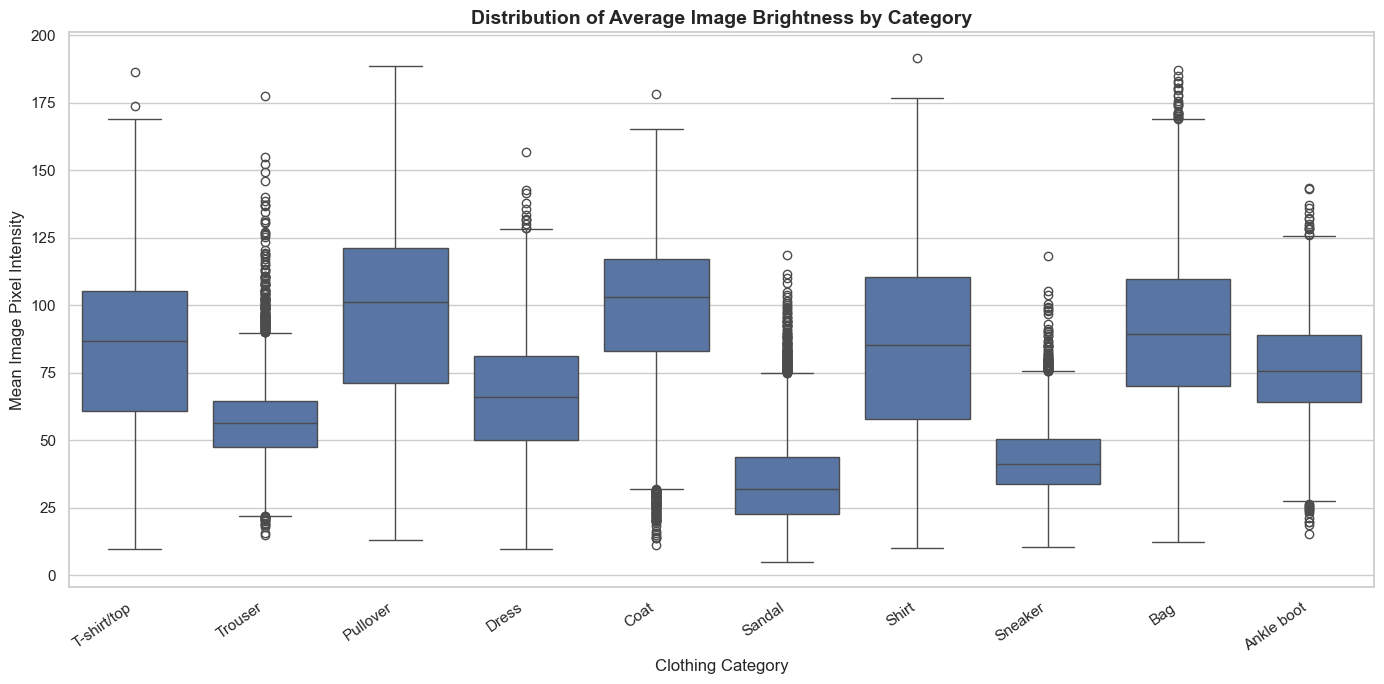

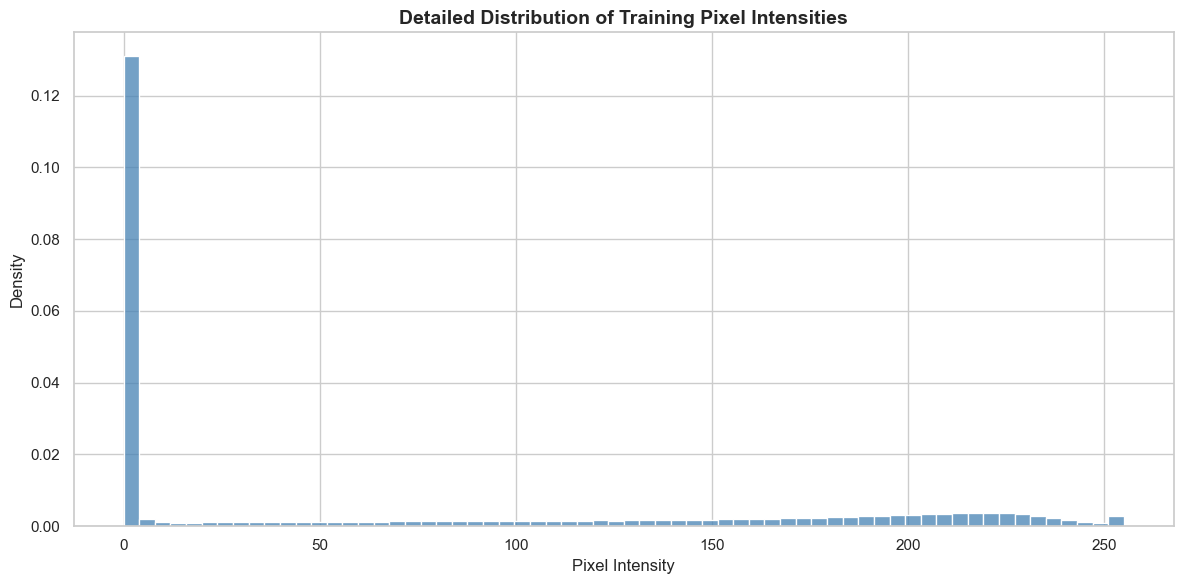

OUTLIER INSPECTION
------------------
Potential brightness outliers: 25
Lower brightness boundary: -27.7
Upper brightness boundary: 172.39


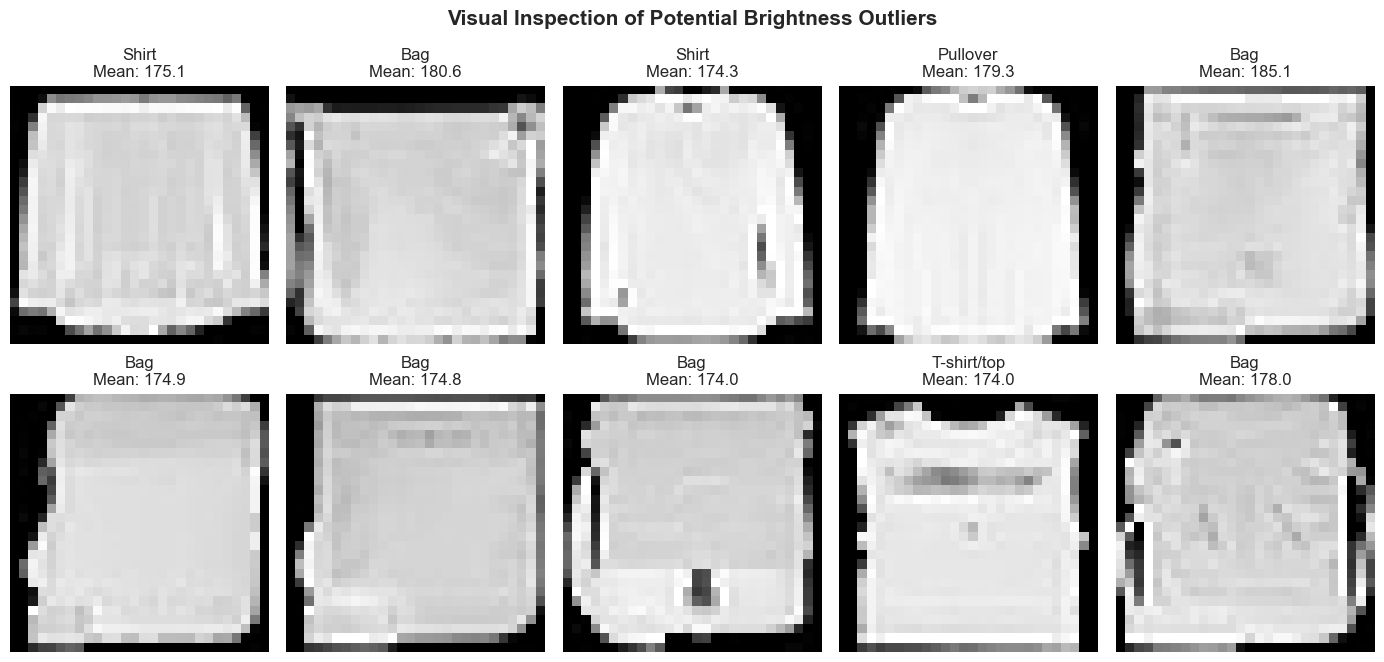


TRAINING AND TESTING CLASS DISTRIBUTION
---------------------------------------
   Category  Training  Testing
T-shirt/top      6000     1000
    Trouser      6000     1000
   Pullover      6000     1000
      Dress      6000     1000
       Coat      6000     1000
     Sandal      6000     1000
      Shirt      6000     1000
    Sneaker      6000     1000
        Bag      6000     1000
 Ankle boot      6000     1000


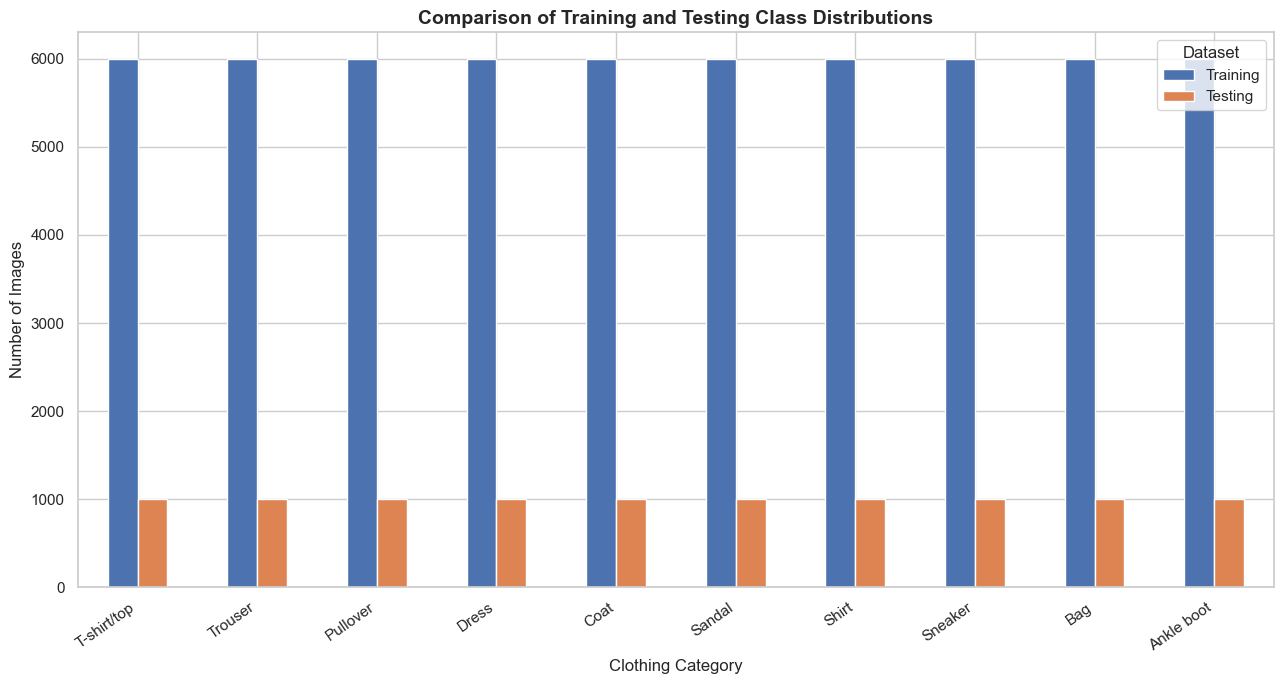


CROSS-DATASET DUPLICATE CHECK
-----------------------------
Exact matching images across training and testing: 0


In [6]:

# STEP 6: ADVANCED EDA VISUALISATIONS AND OUTLIER INSPECTION

# --------------------------------------------------
# VISUAL 9: Category similarity heatmap
# --------------------------------------------------

plt.figure(figsize=(12, 9))

sns.heatmap(
    similarity_df,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.title(
    "Cosine Similarity Between Fashion-MNIST Category Average Images",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Clothing Category")
plt.ylabel("Clothing Category")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# VISUAL 10: Image brightness distribution by category
# --------------------------------------------------

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=intensity_data,
    x="Category",
    y="Mean Intensity",
    order=class_names
)

plt.title(
    "Distribution of Average Image Brightness by Category",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Clothing Category")
plt.ylabel("Mean Image Pixel Intensity")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# VISUAL 11: Detailed pixel intensity histogram
# --------------------------------------------------

plt.figure(figsize=(12, 6))

sns.histplot(
    X_train.flatten(),
    bins=64,
    stat="density",
    color="steelblue"
)

plt.title(
    "Detailed Distribution of Training Pixel Intensities",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Pixel Intensity")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# VISUAL 12: Inspect unusually bright and dark images
# --------------------------------------------------

# Calculate the mean brightness of every training image
brightness = X_train.mean(axis=(1, 2))

# Identify potential outliers using the IQR method
q1 = np.percentile(brightness, 25)
q3 = np.percentile(brightness, 75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_indices = np.where(
    (brightness < lower_bound) |
    (brightness > upper_bound)
)[0]

print("OUTLIER INSPECTION")
print("------------------")
print("Potential brightness outliers:", len(outlier_indices))
print("Lower brightness boundary:", round(lower_bound, 2))
print("Upper brightness boundary:", round(upper_bound, 2))

# Display up to ten unusual images
selected_outliers = outlier_indices[:10]

fig, axes = plt.subplots(2, 5, figsize=(14, 7))

for ax, image_index in zip(axes.flat, selected_outliers):

    ax.imshow(X_train[image_index], cmap="gray")

    label = y_train[image_index]

    ax.set_title(
        f"{class_names[label]}\nMean: {brightness[image_index]:.1f}"
    )

    ax.axis("off")

fig.suptitle(
    "Visual Inspection of Potential Brightness Outliers",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# VISUAL 13: Training and testing class distributions
# --------------------------------------------------

train_counts = np.bincount(y_train, minlength=10)
test_counts = np.bincount(y_test, minlength=10)

distribution_comparison = pd.DataFrame({
    "Category": class_names,
    "Training": train_counts,
    "Testing": test_counts
})

print("\nTRAINING AND TESTING CLASS DISTRIBUTION")
print("---------------------------------------")
print(distribution_comparison.to_string(index=False))

distribution_comparison.plot(
    x="Category",
    y=["Training", "Testing"],
    kind="bar",
    figsize=(13, 7)
)

plt.title(
    "Comparison of Training and Testing Class Distributions",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Clothing Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 7. CROSS-DATASET EXACT DUPLICATE CHECK
# --------------------------------------------------

# Compare image byte representations across training and testing.
# This checks exact pixel-level duplicates between the two sets.

train_hashes = {
    hash(image.tobytes())
    for image in X_train
}

test_hashes = {
    hash(image.tobytes())
    for image in X_test
}

cross_duplicates = len(train_hashes.intersection(test_hashes))

print("\nCROSS-DATASET DUPLICATE CHECK")
print("-----------------------------")
print("Exact matching images across training and testing:",
      cross_duplicates)

COMPLETE OUTLIER INSPECTION
 Image Index    Category  Mean Brightness  Minimum Pixel  Maximum Pixel
         773       Shirt           175.14              0            255
        1909         Bag           180.59              0            255
        8019       Shirt           174.31              0            255
        8156    Pullover           179.34              0            255
        8396         Bag           185.08              0            255
        9107         Bag           174.86              0            255
       17134         Bag           174.80              0            255
       21467         Bag           173.98              0            255
       25544 T-shirt/top           173.98              0            255
       25657         Bag           178.03              0            255
       26778    Pullover           179.68              0            255
       29340         Bag           174.32              0            255
       33011 T-shirt/top           1

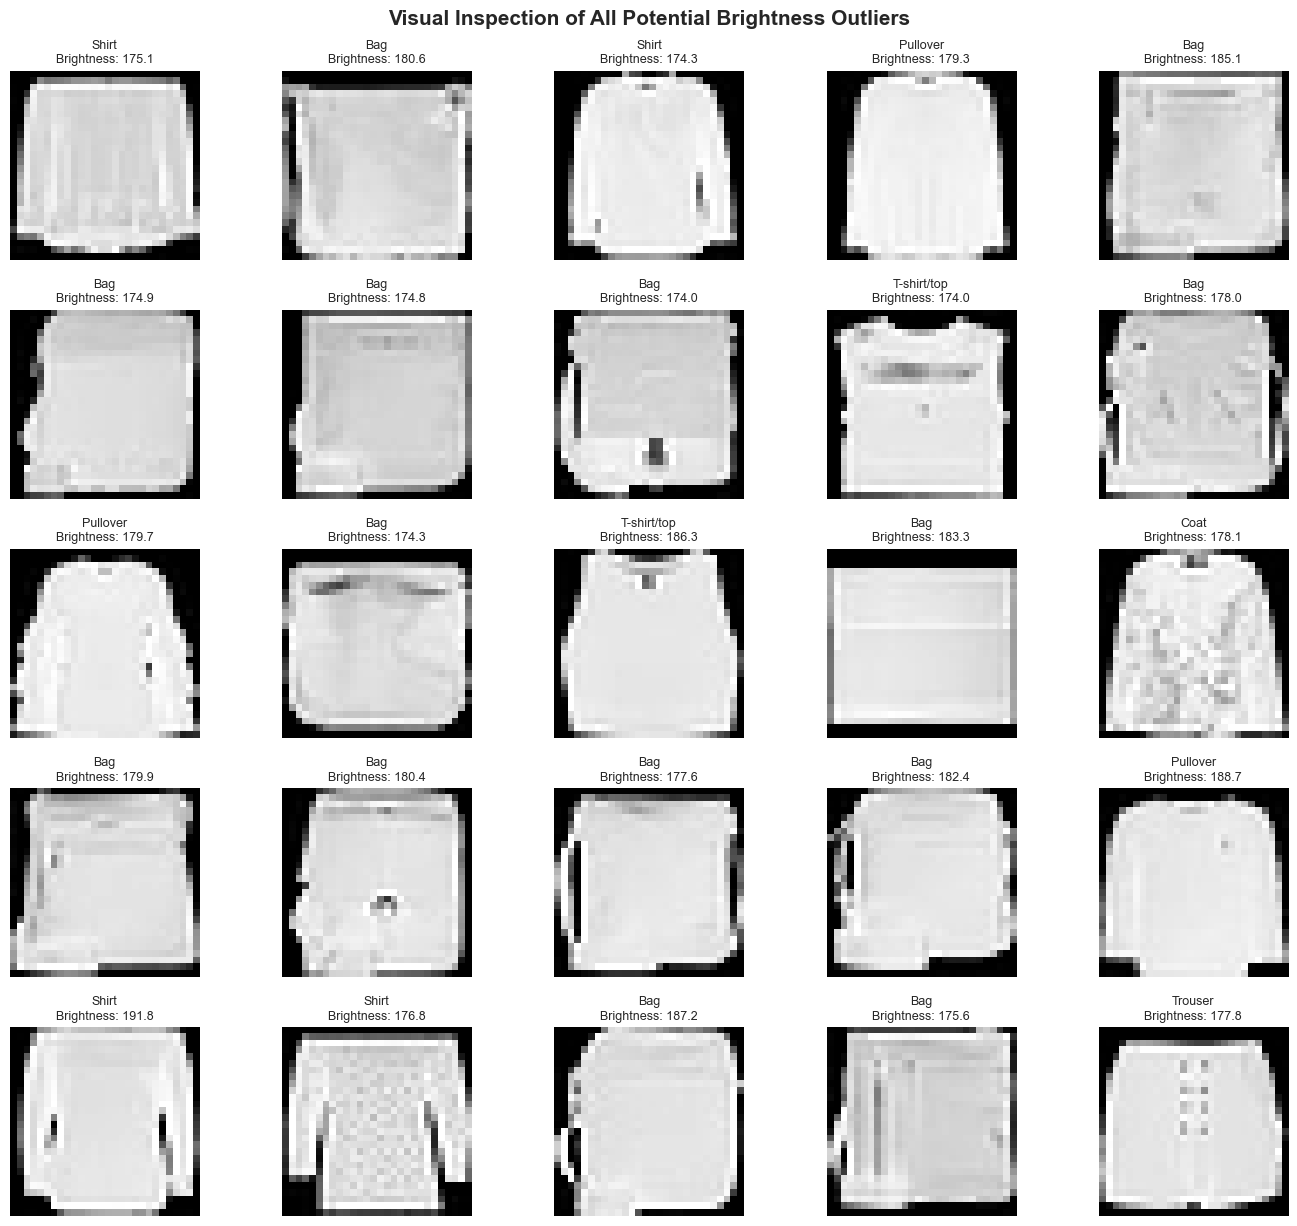

In [7]:

# STEP 7: COMPLETE VISUAL INSPECTION OF ALL POTENTIAL OUTLIERS

print("COMPLETE OUTLIER INSPECTION")
print("=" * 65)

# Prepare an outlier summary
outlier_records = []

for image_index in outlier_indices:

    label = int(y_train[image_index])

    outlier_records.append({
        "Image Index": int(image_index),
        "Category": class_names[label],
        "Mean Brightness": round(float(brightness[image_index]), 2),
        "Minimum Pixel": int(X_train[image_index].min()),
        "Maximum Pixel": int(X_train[image_index].max())
    })

outlier_df = pd.DataFrame(outlier_records)

print(outlier_df.to_string(index=False))

print("\nOUTLIERS BY CATEGORY")
print("--------------------")

print(
    outlier_df["Category"]
    .value_counts()
    .reindex(class_names, fill_value=0)
    .to_string()
)

# Display every identified outlier
number_of_outliers = len(outlier_indices)

if number_of_outliers > 0:

    columns = 5
    rows = int(np.ceil(number_of_outliers / columns))

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(14, rows * 2.5)
    )

    axes = np.array(axes).flatten()

    for position, image_index in enumerate(outlier_indices):

        label = int(y_train[image_index])

        axes[position].imshow(
            X_train[image_index],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[position].set_title(
            f"{class_names[label]}\nBrightness: {brightness[image_index]:.1f}",
            fontsize=9
        )

        axes[position].axis("off")

    # Hide unused subplot positions
    for position in range(number_of_outliers, len(axes)):
        axes[position].axis("off")

    fig.suptitle(
        "Visual Inspection of All Potential Brightness Outliers",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

else:
    print("No potential brightness outliers identified.")

FASHION-MNIST DATA PREPROCESSING

1. ORIGINAL DATASET STRUCTURE
Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)
Original data type: uint8
Original pixel range: 0 to 255

2. AFTER PIXEL NORMALISATION
Training data type: float32
Testing data type: float32
Training minimum: 0.0
Training maximum: 1.0
Training mean: 0.286
Training standard deviation: 0.353

3. AFTER CNN IMAGE RESHAPING
Training CNN input shape: (60000, 28, 28, 1)
Testing CNN input shape: (10000, 28, 28, 1)

4. LABEL PREPARATION
Training labels shape: (60000,)
Testing labels shape: (10000,)
Training label data type: uint8
Unique labels: [0 1 2 3 4 5 6 7 8 9]


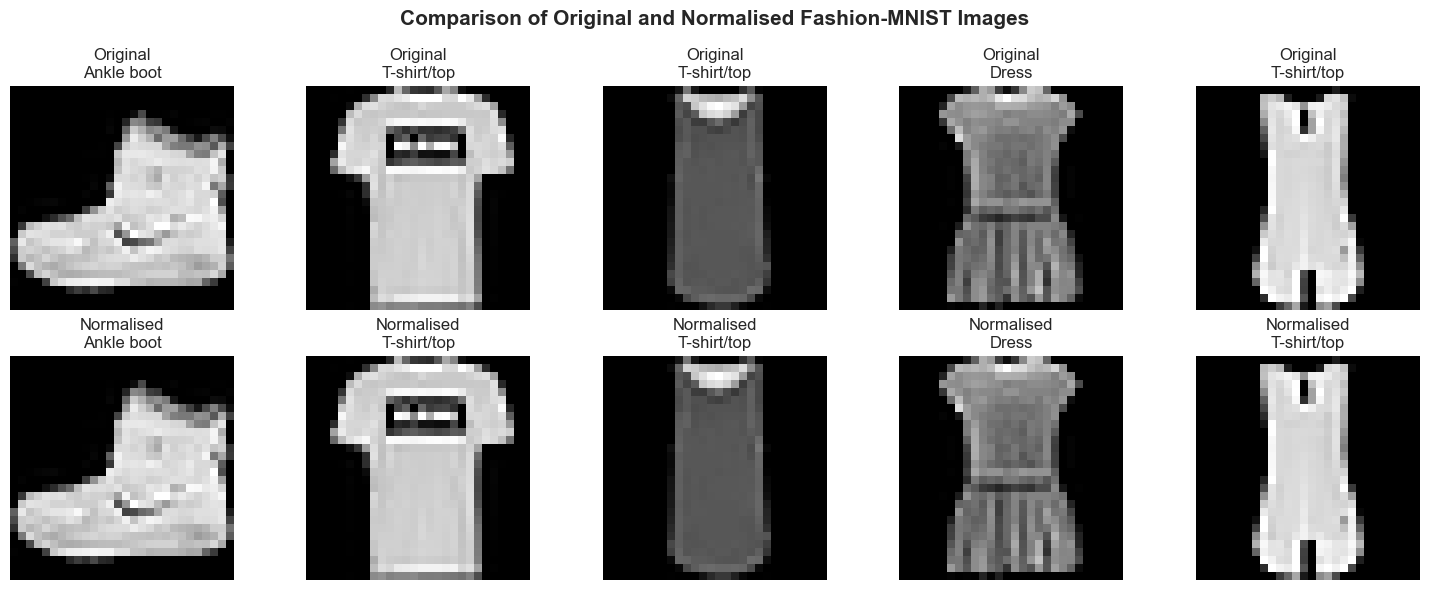

MemoryError: Unable to allocate 359. MiB for an array with shape (47040000,) and data type int64

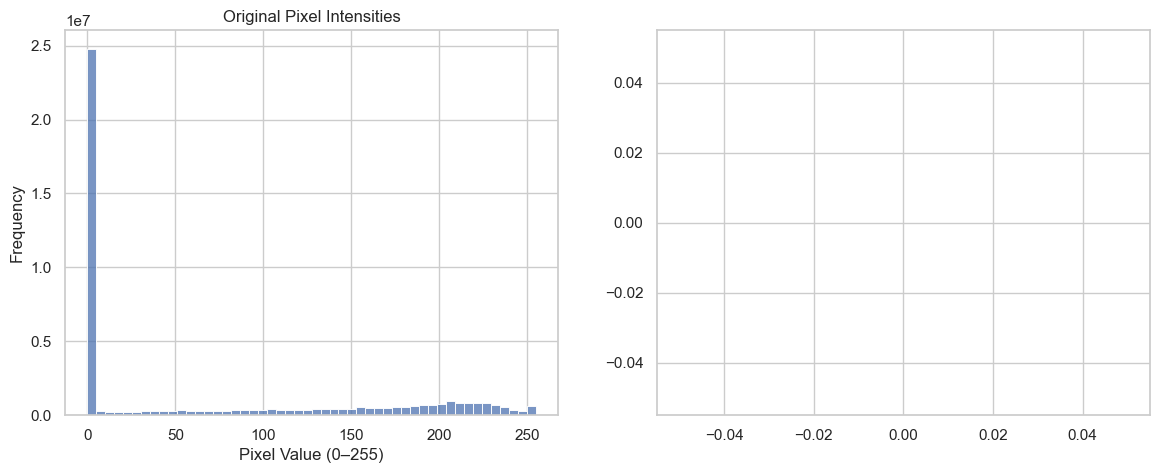

In [8]:

# STEP 8: DATA PREPROCESSING AND NORMALISATION

print("=" * 65)
print("FASHION-MNIST DATA PREPROCESSING")
print("=" * 65)

# --------------------------------------------------
# 1. Preserve the original datasets
# --------------------------------------------------

# Create copies so the original data remains unchanged
X_train_original = X_train.copy()
X_test_original = X_test.copy()

print("\n1. ORIGINAL DATASET STRUCTURE")
print("Training shape:", X_train_original.shape)
print("Testing shape:", X_test_original.shape)
print("Original data type:", X_train_original.dtype)
print("Original pixel range:",
      X_train_original.min(), "to", X_train_original.max())


# --------------------------------------------------
# 2. Normalise pixel intensities
# --------------------------------------------------

# Convert integer pixel values to float32
# Divide by 255 to scale values between 0 and 1

X_train_cnn = X_train_original.astype("float32") / 255.0
X_test_cnn = X_test_original.astype("float32") / 255.0

print("\n2. AFTER PIXEL NORMALISATION")
print("Training data type:", X_train_cnn.dtype)
print("Testing data type:", X_test_cnn.dtype)

print("Training minimum:", X_train_cnn.min())
print("Training maximum:", X_train_cnn.max())
print("Training mean:", round(float(X_train_cnn.mean()), 4))
print("Training standard deviation:",
      round(float(X_train_cnn.std()), 4))


# --------------------------------------------------
# 3. Reshape images for CNN input
# --------------------------------------------------

# Add one channel because the images are grayscale
# The channel dimension is placed at the end

X_train_cnn = np.expand_dims(X_train_cnn, axis=-1)
X_test_cnn = np.expand_dims(X_test_cnn, axis=-1)

print("\n3. AFTER CNN IMAGE RESHAPING")
print("Training CNN input shape:", X_train_cnn.shape)
print("Testing CNN input shape:", X_test_cnn.shape)


# --------------------------------------------------
# 4. Inspect class labels
# --------------------------------------------------

# Keep labels as integers.
# We will use sparse_categorical_crossentropy later.

print("\n4. LABEL PREPARATION")
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)
print("Training label data type:", y_train.dtype)
print("Unique labels:", np.unique(y_train))


# --------------------------------------------------
# 5. Compare original and normalised images
# --------------------------------------------------

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

sample_indices = [0, 1, 2, 3, 4]

for column, index in enumerate(sample_indices):

    # Original image
    axes[0, column].imshow(
        X_train_original[index],
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[0, column].set_title(
        f"Original\n{class_names[y_train[index]]}"
    )

    axes[0, column].axis("off")

    # Normalised image
    axes[1, column].imshow(
        X_train_cnn[index].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, column].set_title(
        f"Normalised\n{class_names[y_train[index]]}"
    )

    axes[1, column].axis("off")

fig.suptitle(
    "Comparison of Original and Normalised Fashion-MNIST Images",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. Compare pixel intensity distributions
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original distribution
sns.histplot(
    X_train_original.flatten(),
    bins=50,
    ax=axes[0]
)

axes[0].set_title("Original Pixel Intensities")
axes[0].set_xlabel("Pixel Value (0–255)")
axes[0].set_ylabel("Frequency")

# Normalised distribution
sns.histplot(
    X_train_cnn.flatten(),
    bins=50,
    ax=axes[1]
)

axes[1].set_title("Normalised Pixel Intensities")
axes[1].set_xlabel("Pixel Value (0–1)")
axes[1].set_ylabel("Frequency")

plt.suptitle(
    "Pixel Intensity Distribution Before and After Normalisation",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 7. Final preprocessing validation
# --------------------------------------------------

print("\n7. PREPROCESSING VALIDATION")
print("---------------------------")

print("Training images:", X_train_cnn.shape[0])
print("Testing images:", X_test_cnn.shape[0])
print("Image height:", X_train_cnn.shape[1])
print("Image width:", X_train_cnn.shape[2])
print("Image channels:", X_train_cnn.shape[3])

print("All training values finite:",
      np.isfinite(X_train_cnn).all())

print("All testing values finite:",
      np.isfinite(X_test_cnn).all())

print("Training values within [0, 1]:",
      X_train_cnn.min() >= 0 and X_train_cnn.max() <= 1)

print("\nPREPROCESSING COMPLETED SUCCESSFULLY")
print("=" * 65)

GENERATING PREPROCESSING VISUALISATIONS


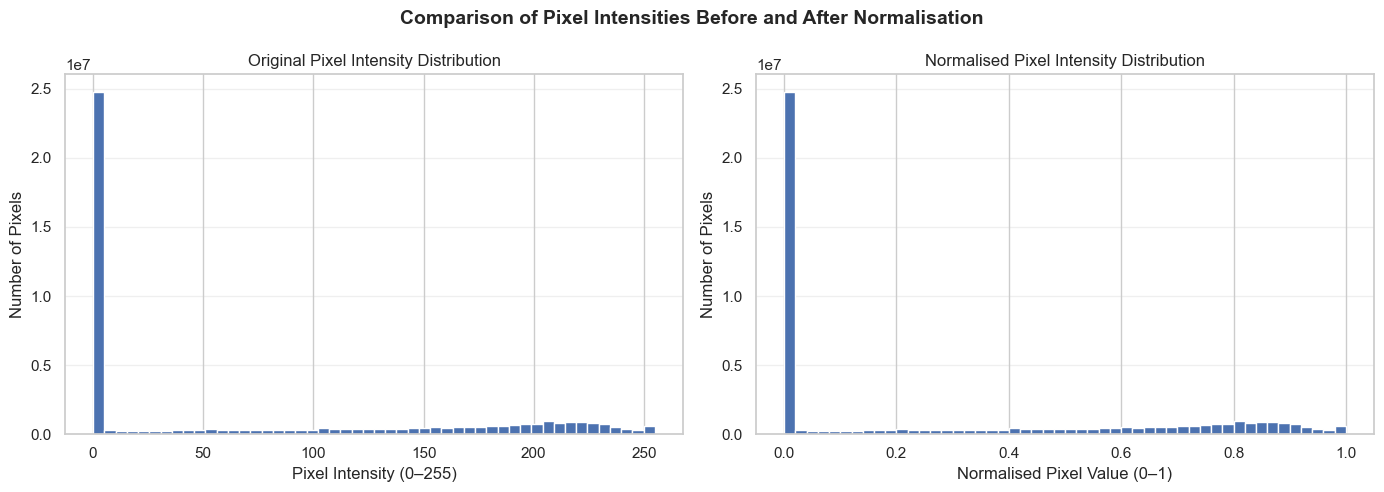

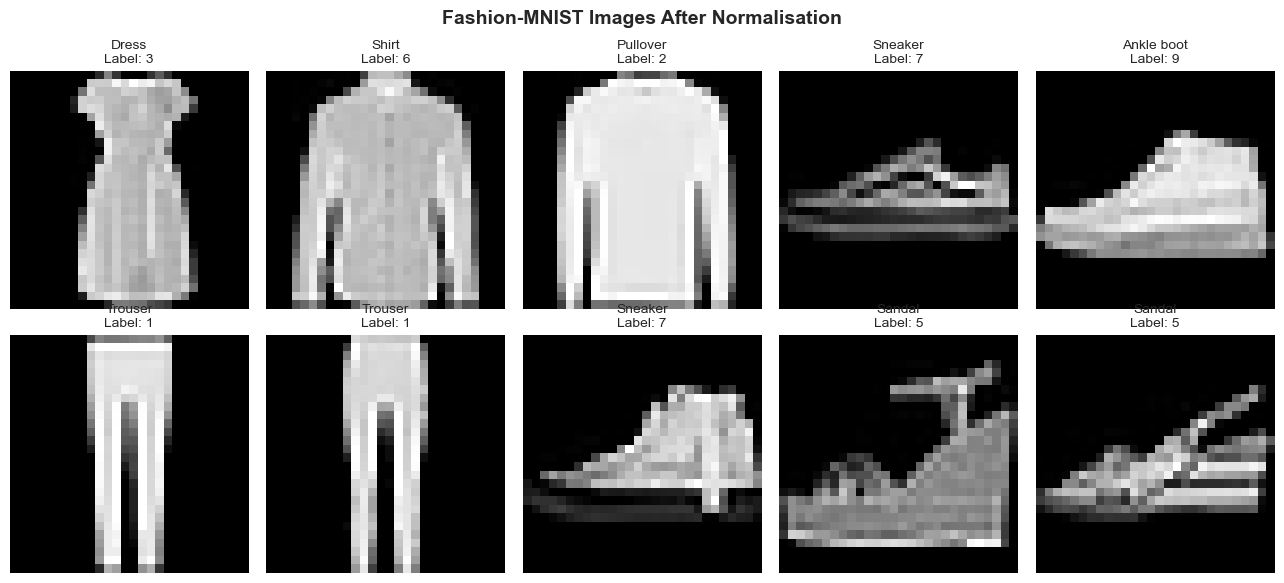


PREPROCESSING VERIFICATION
----------------------------------------
Training input shape: (60000, 28, 28, 1)
Testing input shape:  (10000, 28, 28, 1)
Training minimum: 0.000
Training maximum: 1.000
Training mean:    0.286

Preprocessing visualisations completed.


In [9]:
# STEP 8: MEMORY-EFFICIENT PREPROCESSING VISUALISATIONS

import numpy as np
import matplotlib.pyplot as plt

print("GENERATING PREPROCESSING VISUALISATIONS")
print("=" * 55)

# ---------------------------------------------------------
# VISUAL 1: ORIGINAL VS NORMALISED PIXEL DISTRIBUTIONS
# ---------------------------------------------------------

# Calculate histograms directly without flattening the
# entire dataset into a large additional array.

original_counts, original_bins = np.histogram(
    X_train,
    bins=50,
    range=(0, 255)
)

normalised_counts, normalised_bins = np.histogram(
    X_train_cnn,
    bins=50,
    range=(0, 1)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    original_bins[:-1],
    original_counts,
    width=np.diff(original_bins),
    align="edge"
)

axes[0].set_title("Original Pixel Intensity Distribution")
axes[0].set_xlabel("Pixel Intensity (0–255)")
axes[0].set_ylabel("Number of Pixels")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    normalised_bins[:-1],
    normalised_counts,
    width=np.diff(normalised_bins),
    align="edge"
)

axes[1].set_title("Normalised Pixel Intensity Distribution")
axes[1].set_xlabel("Normalised Pixel Value (0–1)")
axes[1].set_ylabel("Number of Pixels")
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Comparison of Pixel Intensities Before and After Normalisation",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# VISUAL 2: EXAMPLES OF NORMALISED FASHION-MNIST IMAGES
# ---------------------------------------------------------

# Select 10 random training images without copying the
# complete dataset.

rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(X_train_cnn),
    size=10,
    replace=False
)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
axes = axes.flatten()

for position, image_index in enumerate(sample_indices):

    axes[position].imshow(
        X_train_cnn[image_index].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    label = int(y_train[image_index])

    axes[position].set_title(
        f"{class_names[label]}\nLabel: {label}",
        fontsize=10
    )

    axes[position].axis("off")

plt.suptitle(
    "Fashion-MNIST Images After Normalisation",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# VISUAL 3: VERIFY PREPROCESSING STATISTICS
# ---------------------------------------------------------

print("\nPREPROCESSING VERIFICATION")
print("-" * 40)

print(f"Training input shape: {X_train_cnn.shape}")
print(f"Testing input shape:  {X_test_cnn.shape}")

print(f"Training minimum: {X_train_cnn.min():.3f}")
print(f"Training maximum: {X_train_cnn.max():.3f}")
print(f"Training mean:    {X_train_cnn.mean():.3f}")

print("\nPreprocessing visualisations completed.")

In [10]:
# STEP 9: CREATE TRAINING AND VALIDATION DATASETS

from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# Split the original training dataset.
# 80% will be used for model training.
# 20% will be used for validation.
# Stratification preserves the proportion of each category.

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_cnn,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# ---------------------------------------------------------
# 1. VERIFY DATASET DIMENSIONS
# ---------------------------------------------------------

print("TRAINING AND VALIDATION DATA SPLIT")
print("=" * 55)

print(f"Original training dataset: {X_train_cnn.shape}")
print(f"New training dataset:      {X_train_final.shape}")
print(f"Validation dataset:        {X_val.shape}")
print(f"Final testing dataset:     {X_test_cnn.shape}")

print("\nLABEL DIMENSIONS")
print("-" * 40)

print(f"Training labels:   {y_train_final.shape}")
print(f"Validation labels: {y_val.shape}")
print(f"Testing labels:    {y_test.shape}")

# ---------------------------------------------------------
# 2. CHECK CLASS DISTRIBUTION
# ---------------------------------------------------------

distribution_df = pd.DataFrame({
    "Category": class_names,
    "Training": [
        np.sum(y_train_final == i) for i in range(10)
    ],
    "Validation": [
        np.sum(y_val == i) for i in range(10)
    ],
    "Testing": [
        np.sum(y_test == i) for i in range(10)
    ]
})

print("\nCLASS DISTRIBUTION AFTER SPLITTING")
print("-" * 55)

print(distribution_df.to_string(index=False))

# ---------------------------------------------------------
# 3. VERIFY CLASS PROPORTIONS
# ---------------------------------------------------------

print("\nCLASS BALANCE VERIFICATION")
print("-" * 40)

print(
    "Training proportions:",
    np.unique(y_train_final, return_counts=True)[1] / len(y_train_final)
)

print(
    "Validation proportions:",
    np.unique(y_val, return_counts=True)[1] / len(y_val)
)

print(
    "Testing proportions:",
    np.unique(y_test, return_counts=True)[1] / len(y_test)
)

# ---------------------------------------------------------
# 4. CONFIRM DATA INTEGRITY
# ---------------------------------------------------------

assert X_train_final.shape[0] == 48000
assert X_val.shape[0] == 12000
assert X_test_cnn.shape[0] == 10000

assert len(y_train_final) == len(X_train_final)
assert len(y_val) == len(X_val)
assert len(y_test) == len(X_test_cnn)

assert set(y_train_final) == set(range(10))
assert set(y_val) == set(range(10))
assert set(y_test) == set(range(10))

print("\nAll dataset split and label integrity checks passed.")

TRAINING AND VALIDATION DATA SPLIT
Original training dataset: (60000, 28, 28, 1)
New training dataset:      (48000, 28, 28, 1)
Validation dataset:        (12000, 28, 28, 1)
Final testing dataset:     (10000, 28, 28, 1)

LABEL DIMENSIONS
----------------------------------------
Training labels:   (48000,)
Validation labels: (12000,)
Testing labels:    (10000,)

CLASS DISTRIBUTION AFTER SPLITTING
-------------------------------------------------------
   Category  Training  Validation  Testing
T-shirt/top      4800        1200     1000
    Trouser      4800        1200     1000
   Pullover      4800        1200     1000
      Dress      4800        1200     1000
       Coat      4800        1200     1000
     Sandal      4800        1200     1000
      Shirt      4800        1200     1000
    Sneaker      4800        1200     1000
        Bag      4800        1200     1000
 Ankle boot      4800        1200     1000

CLASS BALANCE VERIFICATION
----------------------------------------
Trai

In [11]:
# STEP 10: BUILD AND COMPILE THE BASELINE CNN

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

# Set random seeds to improve reproducibility.
tf.keras.utils.set_random_seed(42)

# ---------------------------------------------------------
# 1. DEFINE THE CNN ARCHITECTURE
# ---------------------------------------------------------

baseline_cnn = Sequential(
    [
        # Input layer: 28 x 28 grayscale image.
        Input(shape=(28, 28, 1), name="input_image"),

        # First convolutional layer:
        # Learns basic visual features such as edges and shapes.
        Conv2D(
            filters=32,
            kernel_size=(3, 3),
            activation="relu",
            padding="same",
            name="convolution_1"
        ),

        # Reduces the spatial dimensions of feature maps.
        MaxPooling2D(
            pool_size=(2, 2),
            name="max_pooling_1"
        ),

        # Second convolutional layer:
        # Learns more complex visual patterns.
        Conv2D(
            filters=64,
            kernel_size=(3, 3),
            activation="relu",
            padding="same",
            name="convolution_2"
        ),

        # Further reduces the spatial dimensions.
        MaxPooling2D(
            pool_size=(2, 2),
            name="max_pooling_2"
        ),

        # Converts the feature maps into a one-dimensional vector.
        Flatten(name="flatten"),

        # Fully connected layer for classification learning.
        Dense(
            units=128,
            activation="relu",
            name="dense_128"
        ),

        # Randomly disables 30% of neurons during training.
        # This helps reduce overfitting.
        Dropout(
            rate=0.30,
            name="dropout"
        ),

        # Output layer: one probability for each of 10 categories.
        Dense(
            units=10,
            activation="softmax",
            name="classification_output"
        )
    ],
    name="Fashion_MNIST_Baseline_CNN"
)

# ---------------------------------------------------------
# 2. COMPILE THE MODEL
# ---------------------------------------------------------

baseline_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ---------------------------------------------------------
# 3. DISPLAY MODEL ARCHITECTURE
# ---------------------------------------------------------

print("BASELINE CNN MODEL SUMMARY")
print("=" * 65)

baseline_cnn.summary()

# ---------------------------------------------------------
# 4. DISPLAY MODEL CONFIGURATION
# ---------------------------------------------------------

print("\nMODEL CONFIGURATION")
print("-" * 45)

print("Architecture:", baseline_cnn.name)
print("Input shape:", baseline_cnn.input_shape)
print("Output shape:", baseline_cnn.output_shape)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Loss function: Sparse categorical cross-entropy")
print("Evaluation metric: Accuracy")

print("\nMODEL PARAMETER COUNTS")
print("-" * 45)

print(
    f"Total parameters: "
    f"{baseline_cnn.count_params():,}"
)

print("\nBaseline CNN built and compiled successfully.")

BASELINE CNN MODEL SUMMARY


Model: "Fashion_MNIST_Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ convolution_1 (Conv2D)          │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling_1 (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convolution_2 (Conv2D)          │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling_2 (MaxPooling2D)    │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_output (Dense)   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)


MODEL CONFIGURATION
---------------------------------------------
Architecture: Fashion_MNIST_Baseline_CNN
Input shape: (None, 28, 28, 1)
Output shape: (None, 10)
Optimizer: Adam
Learning rate: 0.001
Loss function: Sparse categorical cross-entropy
Evaluation metric: Accuracy

MODEL PARAMETER COUNTS
---------------------------------------------
Total parameters: 421,642

Baseline CNN built and compiled successfully.


STARTING BASELINE CNN TRAINING
Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 44s 104ms/step - accuracy: 0.7973 - loss: 0.5666 - val_accuracy: 0.8674 - val_loss: 0.3543 - learning_rate: 0.0010
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 47s 121ms/step - accuracy: 0.8725 - loss: 0.3519 - val_accuracy: 0.8937 - val_loss: 0.2890 - learning_rate: 0.0010
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 52s 138ms/step - accuracy: 0.8915 - loss: 0.3015 - val_accuracy: 0.9053 - val_loss: 0.2627 - learning_rate: 0.0010
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 45s 119ms/step - accuracy: 0.9004 - loss: 0.2739 - val_accuracy: 0.9113 - val_loss: 0.2476 - learning_rate: 0.0010
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 74s 96ms/step - accuracy: 0.9084 - loss: 0.2494 - val_accuracy: 0.9150 - val_loss: 0.2403 - learning_rate: 0.0010
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 39s 103ms/step - accuracy: 0.9141 - loss: 0.2301 - val_accuracy: 0.9173 - val_loss: 0.2301 - learning_rate: 0.0010
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 

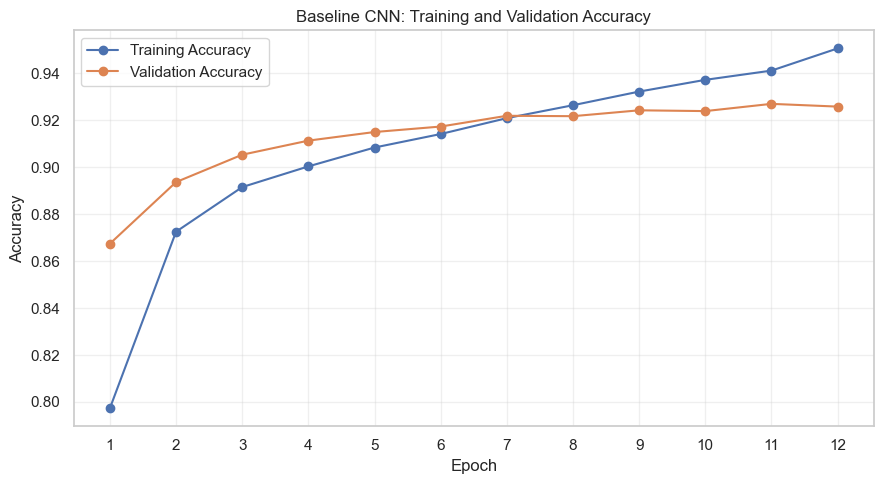

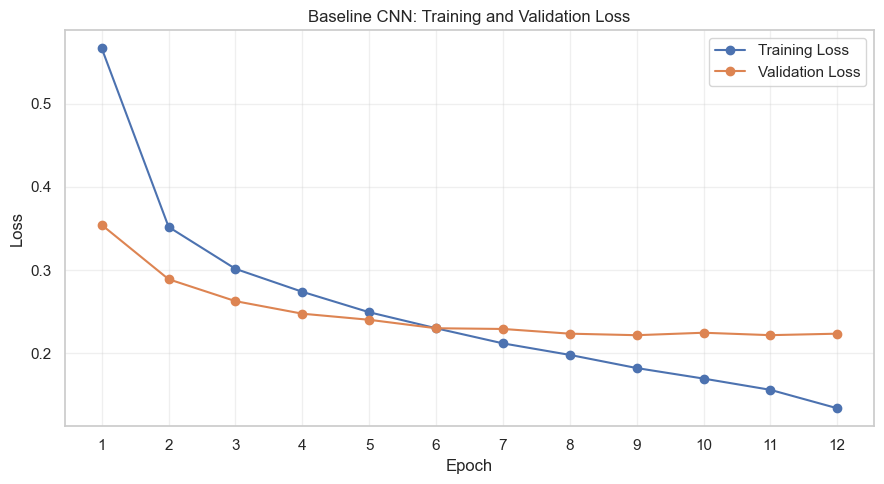

In [12]:
# STEP 11: TRAIN THE BASELINE CNN

import tensorflow as tf
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. CONFIGURE TRAINING PARAMETERS
# ---------------------------------------------------------

EPOCHS = 15
BATCH_SIZE = 128

# Stop training if validation loss does not improve
# for 3 consecutive epochs.
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Reduce the learning rate when validation loss plateaus.
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

# ---------------------------------------------------------
# 2. TRAIN THE MODEL
# ---------------------------------------------------------

print("STARTING BASELINE CNN TRAINING")
print("=" * 60)

baseline_history = baseline_cnn.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("\nBASELINE CNN TRAINING COMPLETED")

# ---------------------------------------------------------
# 3. DISPLAY TRAINING SUMMARY
# ---------------------------------------------------------

completed_epochs = len(baseline_history.history["loss"])

print("\nTRAINING SUMMARY")
print("-" * 45)

print(f"Maximum epochs configured: {EPOCHS}")
print(f"Epochs completed: {completed_epochs}")
print(f"Batch size: {BATCH_SIZE}")

print(
    f"Final training accuracy: "
    f"{baseline_history.history['accuracy'][-1]:.4f}"
)

print(
    f"Final validation accuracy: "
    f"{baseline_history.history['val_accuracy'][-1]:.4f}"
)

print(
    f"Best validation accuracy: "
    f"{max(baseline_history.history['val_accuracy']):.4f}"
)

print(
    f"Lowest validation loss: "
    f"{min(baseline_history.history['val_loss']):.4f}"
)

# ---------------------------------------------------------
# 4. VISUALISE TRAINING AND VALIDATION ACCURACY
# ---------------------------------------------------------

epochs_range = range(1, completed_epochs + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs_range,
    baseline_history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    baseline_history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Baseline CNN: Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. VISUALISE TRAINING AND VALIDATION LOSS
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    epochs_range,
    baseline_history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    baseline_history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Baseline CNN: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

BASELINE CNN: FINAL TEST SET EVALUATION
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9128 - loss: 0.2550

OVERALL TEST PERFORMANCE
---------------------------------------------
Test loss:     0.2550
Test accuracy: 0.9128
Test accuracy: 91.28%
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step

Prediction output shape: (10000, 10)
Predicted labels shape: (10000,)

CLASSIFICATION REPORT
------------------------------------------------------------
              precision    recall  f1-score   support

 T-shirt/top     0.8753    0.8560    0.8655      1000
     Trouser     0.9959    0.9810    0.9884      1000
    Pullover     0.8564    0.8710    0.8637      1000
       Dress     0.9103    0.9240    0.9171      1000
        Coat     0.8214    0.9150    0.8657      1000
      Sandal     0.9888    0.9680    0.9783      1000
       Shirt     0.7825    0.6980    0.7378      1000
     Sneaker     0.9436    0.9710    0.9571      1000
         Bag     0.9859    0.9790    0.9824      1000
  Ankle bo

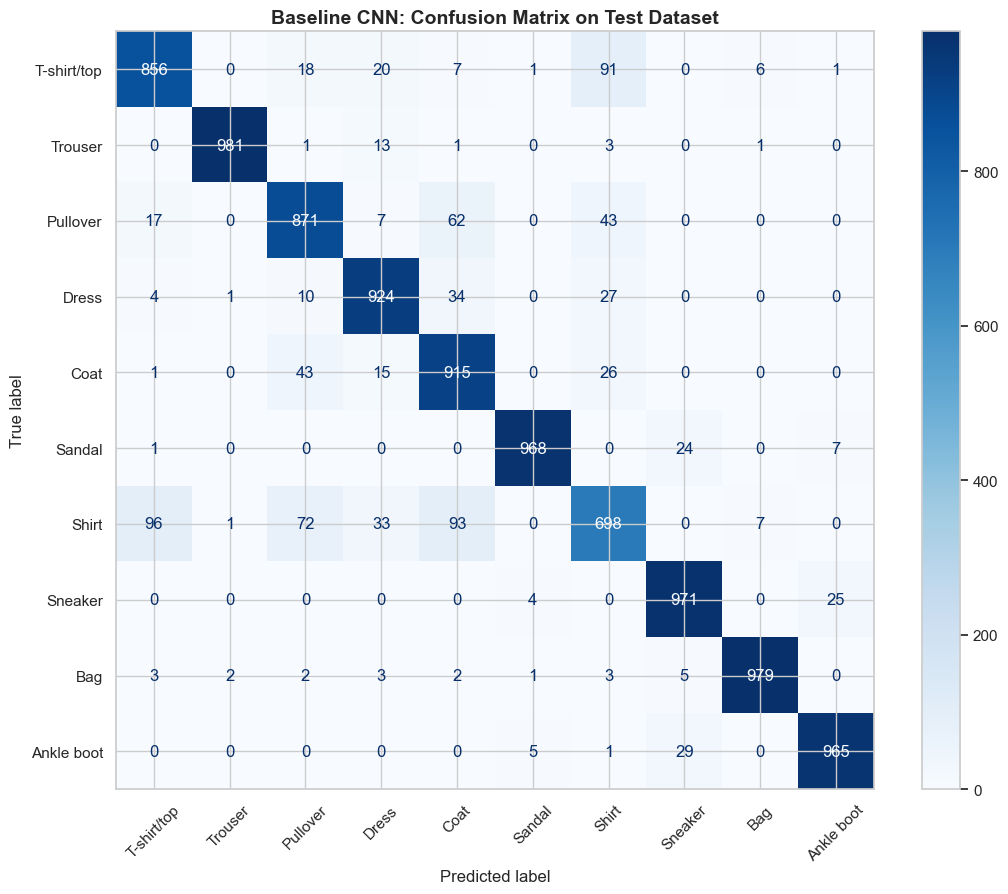

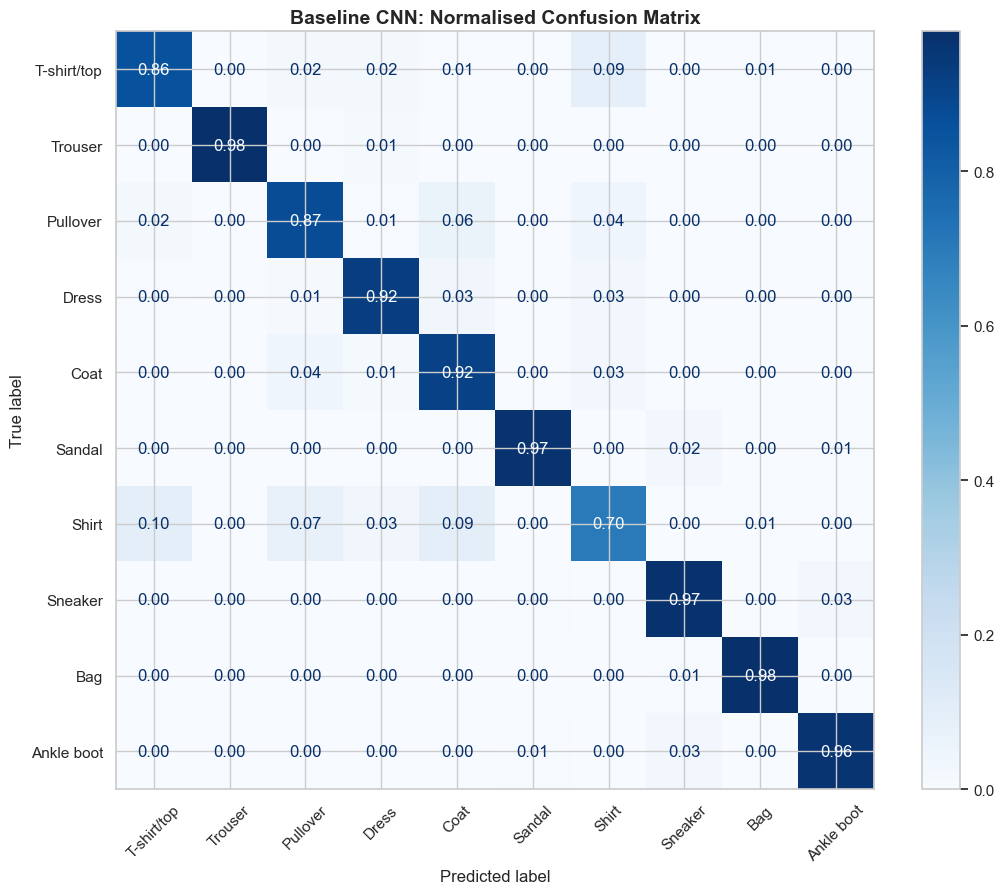


Baseline test evaluation completed.


In [13]:
# STEP 12: EVALUATE THE BASELINE CNN ON THE TEST DATASET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ---------------------------------------------------------
# 1. EVALUATE THE RESTORED BASELINE MODEL
# ---------------------------------------------------------

print("BASELINE CNN: FINAL TEST SET EVALUATION")
print("=" * 60)

test_loss, test_accuracy = baseline_cnn.evaluate(
    X_test_cnn,
    y_test,
    verbose=1
)

print("\nOVERALL TEST PERFORMANCE")
print("-" * 45)

print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

# ---------------------------------------------------------
# 2. GENERATE PREDICTIONS
# ---------------------------------------------------------

y_probabilities = baseline_cnn.predict(
    X_test_cnn,
    batch_size=128,
    verbose=1
)

y_pred = np.argmax(y_probabilities, axis=1)

print("\nPrediction output shape:", y_probabilities.shape)
print("Predicted labels shape:", y_pred.shape)

# ---------------------------------------------------------
# 3. GENERATE CLASSIFICATION REPORT
# ---------------------------------------------------------

print("\nCLASSIFICATION REPORT")
print("-" * 60)

report = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

# ---------------------------------------------------------
# 4. CREATE PER-CLASS PERFORMANCE TABLE
# ---------------------------------------------------------

precision_values = precision_score(
    y_test, y_pred, average=None, zero_division=0
)

recall_values = recall_score(
    y_test, y_pred, average=None, zero_division=0
)

f1_values = f1_score(
    y_test, y_pred, average=None, zero_division=0
)

class_performance = pd.DataFrame({
    "Category": class_names,
    "Precision": precision_values,
    "Recall": recall_values,
    "F1-score": f1_values
})

print("\nPER-CLASS PERFORMANCE")
print("-" * 60)

print(class_performance.round(4).to_string(index=False))

# ---------------------------------------------------------
# 5. CALCULATE MACRO AND WEIGHTED METRICS
# ---------------------------------------------------------

macro_precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

macro_recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

weighted_f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print("\nAGGREGATED PERFORMANCE METRICS")
print("-" * 45)

print(f"Accuracy:         {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro precision:  {macro_precision:.4f}")
print(f"Macro recall:     {macro_recall:.4f}")
print(f"Macro F1-score:   {macro_f1:.4f}")
print(f"Weighted F1-score:{weighted_f1:.4f}")

# ---------------------------------------------------------
# 6. GENERATE CONFUSION MATRIX
# ---------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(11, 9))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=True
)

plt.title(
    "Baseline CNN: Confusion Matrix on Test Dataset",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 7. GENERATE NORMALISED CONFUSION MATRIX
# ---------------------------------------------------------

cm_normalised = confusion_matrix(
    y_test,
    y_pred,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(11, 9))

display_normalised = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalised,
    display_labels=class_names
)

display_normalised.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format=".2f",
    colorbar=True
)

plt.title(
    "Baseline CNN: Normalised Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("\nBaseline test evaluation completed.")

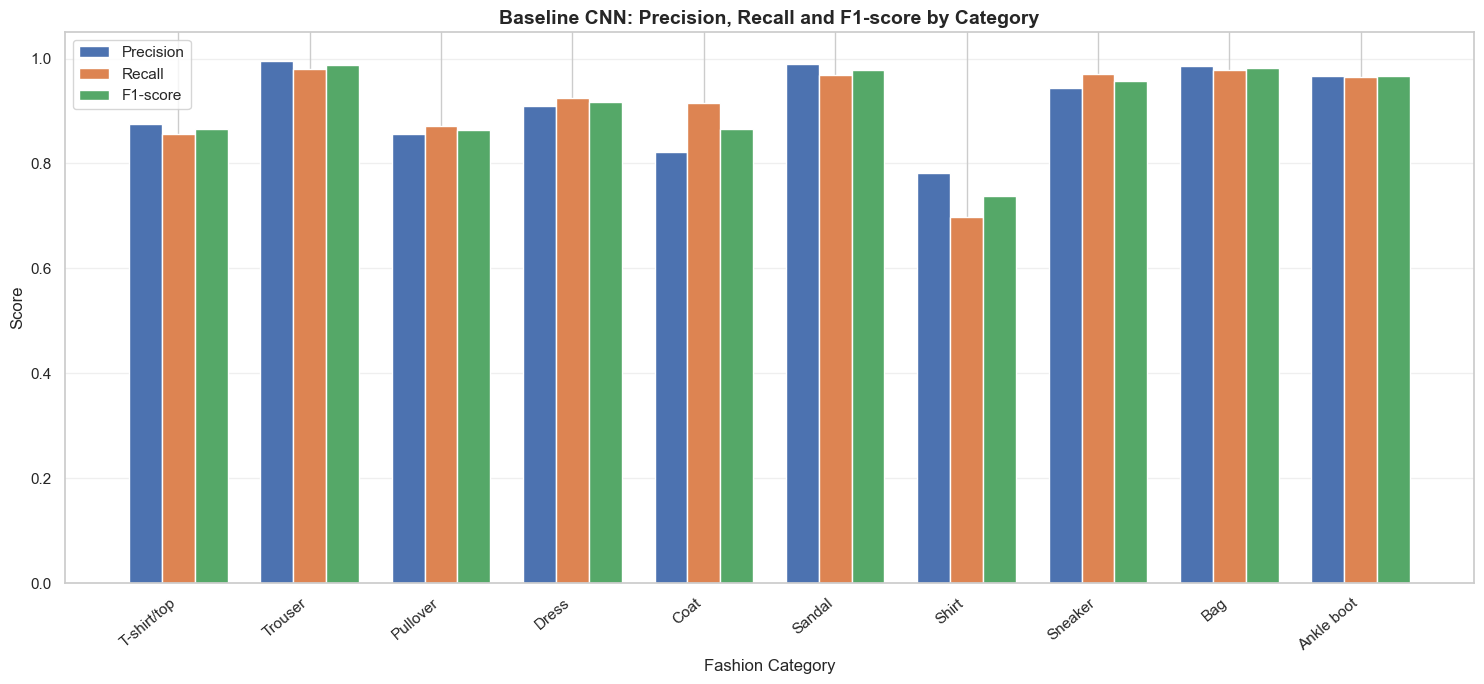

CLASSIFICATION ERROR SUMMARY
Total test images:       10,000
Correct predictions:    9,128
Incorrect predictions:  872
Error rate:              8.72%


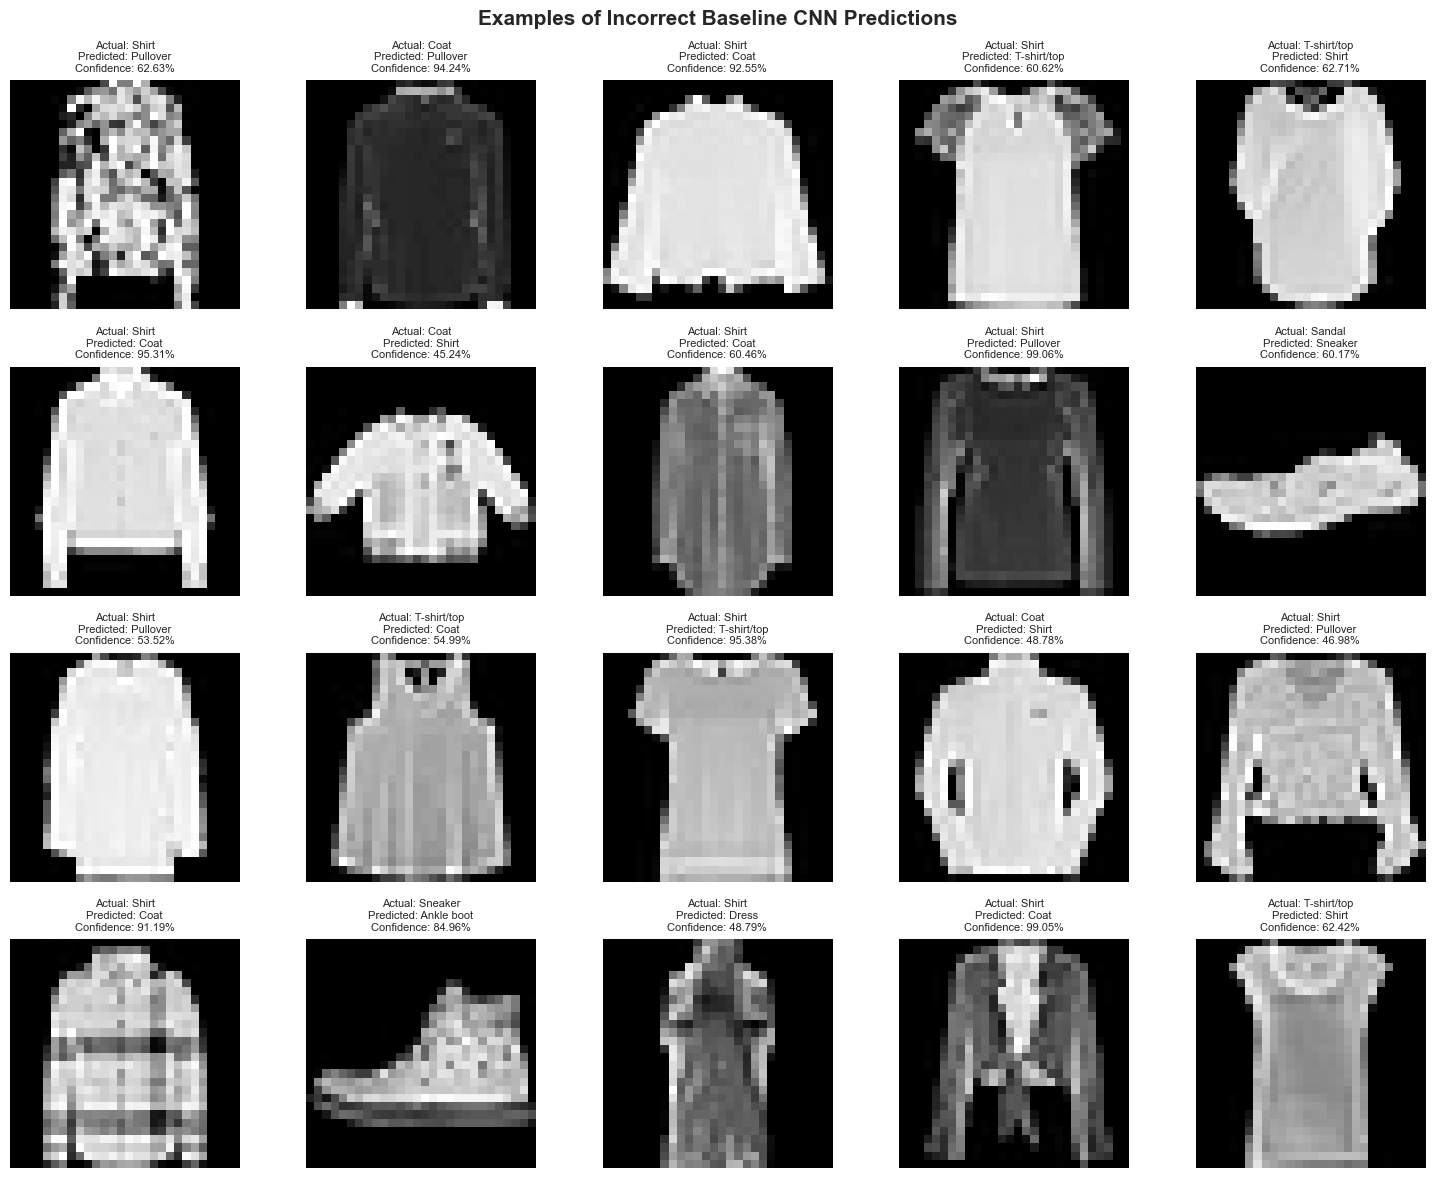


TOP 15 MOST FREQUENT CLASSIFICATION ERRORS
-----------------------------------------------------------------
Actual Category Predicted Category  Number of Errors
          Shirt        T-shirt/top                96
          Shirt               Coat                93
    T-shirt/top              Shirt                91
          Shirt           Pullover                72
       Pullover               Coat                62
       Pullover              Shirt                43
           Coat           Pullover                43
          Dress               Coat                34
          Shirt              Dress                33
     Ankle boot            Sneaker                29
          Dress              Shirt                27
           Coat              Shirt                26
        Sneaker         Ankle boot                25
         Sandal            Sneaker                24
    T-shirt/top              Dress                20


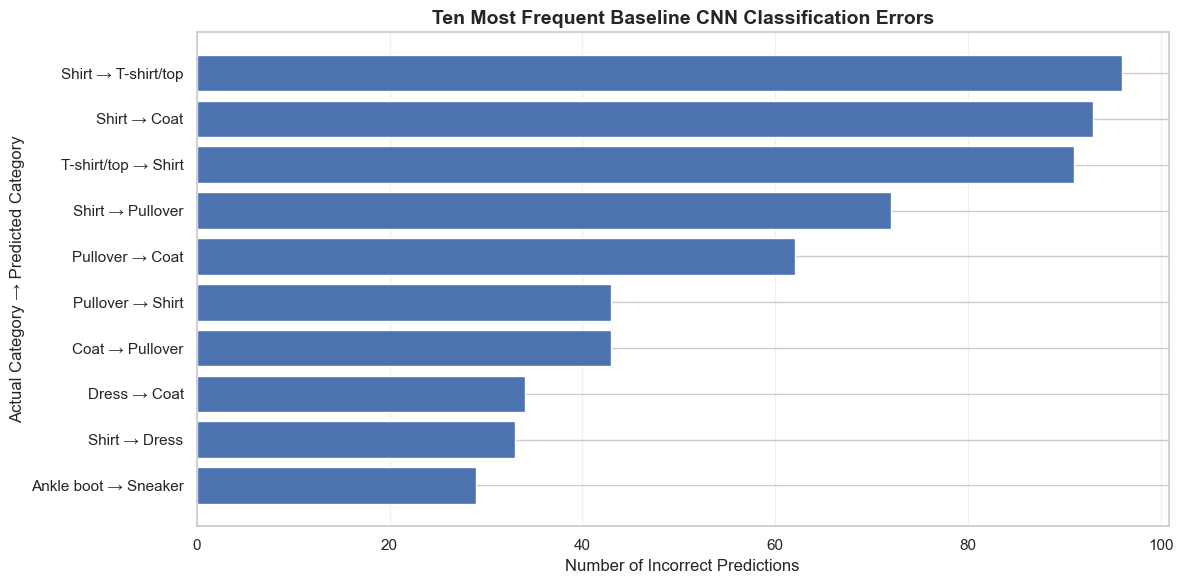


Baseline error analysis completed.


In [14]:
# STEP 13: BASELINE CNN ERROR ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. COMPARE PERFORMANCE ACROSS ALL CATEGORIES
# ---------------------------------------------------------

metrics = ["Precision", "Recall", "F1-score"]

metric_values = [
    precision_values,
    recall_values,
    f1_values
]

x = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(15, 7))

for i, metric in enumerate(metrics):
    ax.bar(
        x + (i - 1) * width,
        metric_values[i],
        width,
        label=metric
    )

ax.set_title(
    "Baseline CNN: Precision, Recall and F1-score by Category",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Fashion Category")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=40, ha="right")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 2. IDENTIFY ALL MISCLASSIFIED IMAGES
# ---------------------------------------------------------

misclassified_indices = np.where(y_pred != y_test)[0]

print("CLASSIFICATION ERROR SUMMARY")
print("=" * 55)

print(f"Total test images:       {len(y_test):,}")
print(f"Correct predictions:    {np.sum(y_pred == y_test):,}")
print(f"Incorrect predictions:  {len(misclassified_indices):,}")
print(
    f"Error rate:              "
    f"{len(misclassified_indices) / len(y_test) * 100:.2f}%"
)

# ---------------------------------------------------------
# 3. DISPLAY EXAMPLES OF INCORRECT PREDICTIONS
# ---------------------------------------------------------

# Select up to 20 examples for visual inspection.
rng = np.random.default_rng(42)

number_to_display = min(20, len(misclassified_indices))

selected_errors = rng.choice(
    misclassified_indices,
    size=number_to_display,
    replace=False
)

fig, axes = plt.subplots(4, 5, figsize=(15, 12))
axes = axes.flatten()

for position, image_index in enumerate(selected_errors):

    axes[position].imshow(
        X_test_cnn[image_index].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    true_label = class_names[int(y_test[image_index])]
    predicted_label = class_names[int(y_pred[image_index])]

    confidence = float(np.max(y_probabilities[image_index]))

    axes[position].set_title(
        f"Actual: {true_label}\n"
        f"Predicted: {predicted_label}\n"
        f"Confidence: {confidence:.2%}",
        fontsize=8
    )

    axes[position].axis("off")

for position in range(number_to_display, len(axes)):
    axes[position].axis("off")

plt.suptitle(
    "Examples of Incorrect Baseline CNN Predictions",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 4. IDENTIFY THE MOST FREQUENT CLASSIFICATION ERRORS
# ---------------------------------------------------------

error_records = []

for actual_class in range(10):

    for predicted_class in range(10):

        if actual_class != predicted_class:

            error_count = np.sum(
                (y_test == actual_class) &
                (y_pred == predicted_class)
            )

            if error_count > 0:
                error_records.append({
                    "Actual Category": class_names[actual_class],
                    "Predicted Category": class_names[predicted_class],
                    "Number of Errors": int(error_count)
                })

error_df = pd.DataFrame(error_records)

error_df = error_df.sort_values(
    by="Number of Errors",
    ascending=False
).reset_index(drop=True)

print("\nTOP 15 MOST FREQUENT CLASSIFICATION ERRORS")
print("-" * 65)

print(error_df.head(15).to_string(index=False))


# ---------------------------------------------------------
# 5. VISUALISE THE TEN MOST FREQUENT ERROR PAIRS
# ---------------------------------------------------------

top_errors = error_df.head(10).copy()

top_errors["Error Pair"] = (
    top_errors["Actual Category"]
    + " → "
    + top_errors["Predicted Category"]
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    top_errors["Error Pair"][::-1],
    top_errors["Number of Errors"][::-1]
)

ax.set_title(
    "Ten Most Frequent Baseline CNN Classification Errors",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Number of Incorrect Predictions")
ax.set_ylabel("Actual Category → Predicted Category")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nBaseline error analysis completed.")

In [15]:
# STEP 14: BUILD THE IMPROVED CNN

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    RandomRotation,
    RandomTranslation,
    RandomZoom,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

# ---------------------------------------------------------
# 1. DEFINE THE IMPROVED CNN ARCHITECTURE
# ---------------------------------------------------------

improved_cnn = Sequential(
    [

        # Input layer
        Input(shape=(28, 28, 1), name="input_image"),

        # -------------------------------------------------
        # DATA AUGMENTATION
        # Applied during training, not validation/testing.
        # -------------------------------------------------

        RandomRotation(
            factor=0.03,
            name="random_rotation"
        ),

        RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            name="random_translation"
        ),

        RandomZoom(
            height_factor=0.10,
            width_factor=0.10,
            name="random_zoom"
        ),

        # -------------------------------------------------
        # FIRST CONVOLUTIONAL BLOCK
        # -------------------------------------------------

        Conv2D(
            32,
            (3, 3),
            padding="same",
            use_bias=False,
            name="conv_1"
        ),

        BatchNormalization(name="batch_norm_1"),
        tf.keras.layers.Activation("relu"),

        Conv2D(
            32,
            (3, 3),
            padding="same",
            activation="relu",
            name="conv_2"
        ),

        MaxPooling2D((2, 2), name="pool_1"),
        Dropout(0.15, name="dropout_1"),

        # -------------------------------------------------
        # SECOND CONVOLUTIONAL BLOCK
        # -------------------------------------------------

        Conv2D(
            64,
            (3, 3),
            padding="same",
            use_bias=False,
            name="conv_3"
        ),

        BatchNormalization(name="batch_norm_2"),
        tf.keras.layers.Activation("relu"),

        Conv2D(
            64,
            (3, 3),
            padding="same",
            activation="relu",
            name="conv_4"
        ),

        MaxPooling2D((2, 2), name="pool_2"),
        Dropout(0.20, name="dropout_2"),

        # -------------------------------------------------
        # THIRD CONVOLUTIONAL BLOCK
        # -------------------------------------------------

        Conv2D(
            128,
            (3, 3),
            padding="same",
            activation="relu",
            name="conv_5"
        ),

        # -------------------------------------------------
        # FEATURE AGGREGATION
        # -------------------------------------------------

        GlobalAveragePooling2D(
            name="global_average_pooling"
        ),

        # -------------------------------------------------
        # CLASSIFICATION LAYERS
        # -------------------------------------------------

        Dense(
            128,
            activation="relu",
            name="dense_128"
        ),

        Dropout(
            0.40,
            name="dropout_3"
        ),

        Dense(
            10,
            activation="softmax",
            name="classification_output"
        )

    ],
    name="Fashion_MNIST_Improved_CNN"
)

# ---------------------------------------------------------
# 2. COMPILE THE IMPROVED MODEL
# ---------------------------------------------------------

improved_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ---------------------------------------------------------
# 3. DISPLAY MODEL SUMMARY
# ---------------------------------------------------------

print("IMPROVED CNN MODEL SUMMARY")
print("=" * 65)

improved_cnn.summary()

print("\nIMPROVED MODEL CONFIGURATION")
print("-" * 50)

print("Architecture:", improved_cnn.name)
print("Input shape:", improved_cnn.input_shape)
print("Output shape:", improved_cnn.output_shape)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Loss function: Sparse categorical cross-entropy")
print("Data augmentation: Rotation, translation and zoom")
print("Batch normalisation: Enabled")
print("Final dropout rate: 0.40")
print("Feature aggregation: Global average pooling")

print("\nPARAMETER COMPARISON")
print("-" * 50)

print(f"Baseline parameters: {baseline_cnn.count_params():,}")
print(f"Improved parameters: {improved_cnn.count_params():,}")

print("\nImproved CNN built and compiled successfully.")

IMPROVED CNN MODEL SUMMARY


Model: "Fashion_MNIST_Improved_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_5 (Conv2D)                 │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_output (Dense)   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 156,938 (613.04 KB)

 Trainable params: 156,746 (612.29 KB)

 Non-trainable params: 192 (768.00 B)


IMPROVED MODEL CONFIGURATION
--------------------------------------------------
Architecture: Fashion_MNIST_Improved_CNN
Input shape: (None, 28, 28, 1)
Output shape: (None, 10)
Optimizer: Adam
Learning rate: 0.001
Loss function: Sparse categorical cross-entropy
Data augmentation: Rotation, translation and zoom
Batch normalisation: Enabled
Final dropout rate: 0.40
Feature aggregation: Global average pooling

PARAMETER COMPARISON
--------------------------------------------------
Baseline parameters: 421,642
Improved parameters: 156,938

Improved CNN built and compiled successfully.


STARTING IMPROVED CNN TRAINING
Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 182s 457ms/step - accuracy: 0.6535 - loss: 0.9318 - val_accuracy: 0.1544 - val_loss: 4.8350 - learning_rate: 0.0010
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 190s 508ms/step - accuracy: 0.7914 - loss: 0.5716 - val_accuracy: 0.8384 - val_loss: 0.4381 - learning_rate: 0.0010
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 213s 569ms/step - accuracy: 0.8257 - loss: 0.4750 - val_accuracy: 0.8445 - val_loss: 0.4232 - learning_rate: 0.0010
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 173s 462ms/step - accuracy: 0.8456 - loss: 0.4241 - val_accuracy: 0.8654 - val_loss: 0.3653 - learning_rate: 0.0010
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 209s 557ms/step - accuracy: 0.8544 - loss: 0.3956 - val_accuracy: 0.8713 - val_loss: 0.3448 - learning_rate: 0.0010
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 171s 456ms/step - accuracy: 0.8652 - loss: 0.3746 - val_accuracy: 0.8795 - val_loss: 0.3220 - learning_rate: 0.0010
Epoch 7/20
375/375 ━━━━━━━━━━━━━━

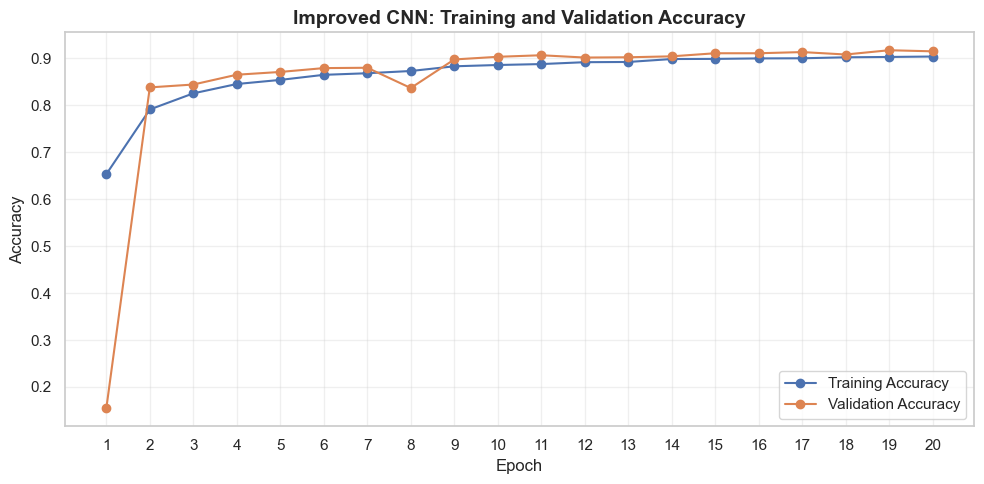

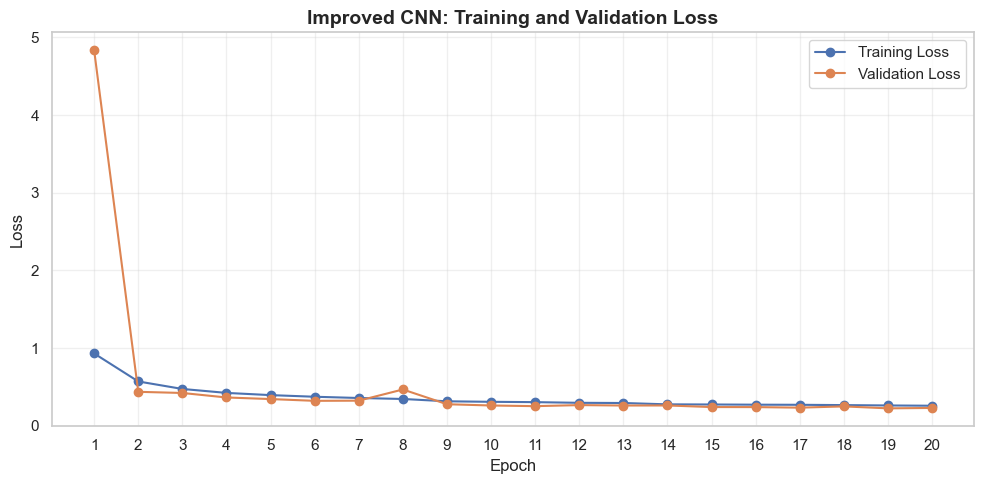

In [16]:
# STEP 15: TRAIN THE IMPROVED CNN

import tensorflow as tf
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. CONFIGURE TRAINING PARAMETERS
# ---------------------------------------------------------

EPOCHS_IMPROVED = 20
BATCH_SIZE_IMPROVED = 128

# Stop if validation loss does not improve for 4 epochs.
improved_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

# Reduce the learning rate when validation loss plateaus.
improved_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

# ---------------------------------------------------------
# 2. TRAIN THE IMPROVED MODEL
# ---------------------------------------------------------

print("STARTING IMPROVED CNN TRAINING")
print("=" * 60)

improved_history = improved_cnn.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_IMPROVED,
    batch_size=BATCH_SIZE_IMPROVED,
    callbacks=[
        improved_early_stopping,
        improved_reduce_lr
    ],
    verbose=1
)

print("\nIMPROVED CNN TRAINING COMPLETED")

# ---------------------------------------------------------
# 3. DISPLAY TRAINING SUMMARY
# ---------------------------------------------------------

improved_epochs_completed = len(
    improved_history.history["loss"]
)

best_improved_epoch = (
    int(
        tf.argmin(
            improved_history.history["val_loss"]
        ).numpy()
    ) + 1
)

print("\nIMPROVED MODEL TRAINING SUMMARY")
print("-" * 50)

print(f"Maximum epochs configured: {EPOCHS_IMPROVED}")
print(f"Epochs completed: {improved_epochs_completed}")
print(f"Batch size: {BATCH_SIZE_IMPROVED}")

print(
    f"Final training accuracy: "
    f"{improved_history.history['accuracy'][-1]:.4f}"
)

print(
    f"Final validation accuracy: "
    f"{improved_history.history['val_accuracy'][-1]:.4f}"
)

print(
    f"Best validation accuracy: "
    f"{max(improved_history.history['val_accuracy']):.4f}"
)

print(
    f"Lowest validation loss: "
    f"{min(improved_history.history['val_loss']):.4f}"
)

print(f"Epoch with lowest validation loss: {best_improved_epoch}")

# ---------------------------------------------------------
# 4. VISUALISE TRAINING AND VALIDATION ACCURACY
# ---------------------------------------------------------

epochs_range = range(1, improved_epochs_completed + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    improved_history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    improved_history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title(
    "Improved CNN: Training and Validation Accuracy",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. VISUALISE TRAINING AND VALIDATION LOSS
# ---------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    improved_history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    improved_history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title(
    "Improved CNN: Training and Validation Loss",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# STEP 16: IMPROVED CNN TRAINING DIAGNOSTICS
# Automatically summarise training performance and compare it
# with the baseline CNN.

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. EXTRACT IMPROVED CNN TRAINING HISTORY
# ---------------------------------------------------------

history_data = improved_history.history

improved_train_acc = np.array(history_data["accuracy"])
improved_val_acc = np.array(history_data["val_accuracy"])
improved_train_loss = np.array(history_data["loss"])
improved_val_loss = np.array(history_data["val_loss"])

best_val_acc_epoch = int(np.argmax(improved_val_acc)) + 1
best_val_loss_epoch = int(np.argmin(improved_val_loss)) + 1

# ---------------------------------------------------------
# 2. DISPLAY EPOCH-BY-EPOCH PERFORMANCE
# ---------------------------------------------------------

training_results = pd.DataFrame({
    "Epoch": range(1, len(improved_train_acc) + 1),
    "Training Accuracy": improved_train_acc,
    "Validation Accuracy": improved_val_acc,
    "Training Loss": improved_train_loss,
    "Validation Loss": improved_val_loss
})

print("=" * 75)
print("IMPROVED CNN: COMPLETE TRAINING HISTORY")
print("=" * 75)

print(training_results.round(4).to_string(index=False))

# ---------------------------------------------------------
# 3. IDENTIFY BEST TRAINING RESULTS
# ---------------------------------------------------------

print("\n" + "=" * 75)
print("IMPROVED CNN: BEST PERFORMANCE")
print("=" * 75)

print(f"Epochs completed: {len(improved_train_acc)}")

print(
    f"Best training accuracy: "
    f"{np.max(improved_train_acc):.4f} "
    f"({np.max(improved_train_acc) * 100:.2f}%)"
)

print(
    f"Best validation accuracy: "
    f"{np.max(improved_val_acc):.4f} "
    f"({np.max(improved_val_acc) * 100:.2f}%)"
)

print(f"Best validation accuracy epoch: {best_val_acc_epoch}")

print(
    f"Lowest training loss: "
    f"{np.min(improved_train_loss):.4f}"
)

print(
    f"Lowest validation loss: "
    f"{np.min(improved_val_loss):.4f}"
)

print(f"Lowest validation loss epoch: {best_val_loss_epoch}")

# ---------------------------------------------------------
# 4. MEASURE OVERFITTING
# ---------------------------------------------------------

best_epoch_train_acc = improved_train_acc[best_val_loss_epoch - 1]
best_epoch_val_acc = improved_val_acc[best_val_loss_epoch - 1]

accuracy_gap = best_epoch_train_acc - best_epoch_val_acc

print("\n" + "=" * 75)
print("OVERFITTING DIAGNOSTICS")
print("=" * 75)

print(
    f"Training accuracy at best validation-loss epoch: "
    f"{best_epoch_train_acc:.4f}"
)

print(
    f"Validation accuracy at best validation-loss epoch: "
    f"{best_epoch_val_acc:.4f}"
)

print(f"Training-validation accuracy gap: {accuracy_gap:.4f}")
print(f"Training-validation accuracy gap (%): {accuracy_gap * 100:.2f}%")

if accuracy_gap <= 0.02:
    print("Diagnostic: Small training-validation accuracy gap.")
elif accuracy_gap <= 0.05:
    print("Diagnostic: Moderate training-validation accuracy gap.")
else:
    print("Diagnostic: Relatively large training-validation accuracy gap.")

# ---------------------------------------------------------
# 5. COMPARE AGAINST BASELINE CNN
# ---------------------------------------------------------

baseline_best_val_acc = max(
    baseline_history.history["val_accuracy"]
)

baseline_best_val_loss = min(
    baseline_history.history["val_loss"]
)

baseline_test_accuracy = test_accuracy
baseline_test_loss = test_loss

improved_best_val_acc = np.max(improved_val_acc)
improved_best_val_loss = np.min(improved_val_loss)

print("\n" + "=" * 75)
print("BASELINE VS IMPROVED CNN: VALIDATION COMPARISON")
print("=" * 75)

comparison = pd.DataFrame({
    "Metric": [
        "Best validation accuracy",
        "Lowest validation loss"
    ],
    "Baseline CNN": [
        baseline_best_val_acc,
        baseline_best_val_loss
    ],
    "Improved CNN": [
        improved_best_val_acc,
        improved_best_val_loss
    ]
})

print(comparison.round(4).to_string(index=False))

accuracy_change = improved_best_val_acc - baseline_best_val_acc
loss_change = improved_best_val_loss - baseline_best_val_loss

print("\nVALIDATION PERFORMANCE CHANGES")
print(f"Accuracy change: {accuracy_change:+.4f}")
print(f"Accuracy change (percentage points): {accuracy_change * 100:+.2f}")
print(f"Validation loss change: {loss_change:+.4f}")

# ---------------------------------------------------------
# 6. PARAMETER EFFICIENCY
# ---------------------------------------------------------

baseline_parameters = baseline_cnn.count_params()
improved_parameters = improved_cnn.count_params()

parameter_reduction = (
    (baseline_parameters - improved_parameters)
    / baseline_parameters
) * 100

print("\n" + "=" * 75)
print("MODEL COMPLEXITY COMPARISON")
print("=" * 75)

print(f"Baseline parameters: {baseline_parameters:,}")
print(f"Improved parameters: {improved_parameters:,}")
print(f"Parameter reduction: {parameter_reduction:.2f}%")

# ---------------------------------------------------------
# 7. AUTOMATED INTERPRETATION
# ---------------------------------------------------------

print("\n" + "=" * 75)
print("AUTOMATED TRAINING INTERPRETATION")
print("=" * 75)

if accuracy_change > 0:
    print("Validation accuracy: Improved CNN performed better.")
elif accuracy_change < 0:
    print("Validation accuracy: Baseline CNN performed better.")
else:
    print("Validation accuracy: Both models achieved the same result.")

if loss_change < 0:
    print("Validation loss: Improved CNN achieved a lower loss.")
elif loss_change > 0:
    print("Validation loss: Baseline CNN achieved a lower loss.")
else:
    print("Validation loss: Both models achieved the same result.")

print("\nIMPORTANT:")
print(
    "These are training and validation results. "
    "The final comparison must use the untouched test dataset."
)

print("\nDIAGNOSTIC REPORT COMPLETED.")

IMPROVED CNN: COMPLETE TRAINING HISTORY
 Epoch  Training Accuracy  Validation Accuracy  Training Loss  Validation Loss
     1             0.6535               0.1544         0.9318           4.8350
     2             0.7914               0.8384         0.5716           0.4381
     3             0.8257               0.8445         0.4750           0.4232
     4             0.8456               0.8654         0.4241           0.3653
     5             0.8544               0.8713         0.3956           0.3448
     6             0.8652               0.8795         0.3746           0.3220
     7             0.8686               0.8802         0.3586           0.3241
     8             0.8733               0.8371         0.3460           0.4681
     9             0.8834               0.8979         0.3160           0.2783
    10             0.8861               0.9036         0.3094           0.2620
    11             0.8881               0.9069         0.3052           0.2535
    12      

In [18]:
# STEP 17: RETRAIN IMPROVED CNN WITH BEST-WEIGHT CHECKPOINTING

import tensorflow as tf
import numpy as np
import os

# Save the best model weights in the current notebook directory.
checkpoint_path = "best_improved_cnn.weights.h5"

# Save weights whenever validation loss improves.
best_model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    mode="min",
    verbose=1
)

# Learning-rate adjustment.
checkpoint_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

print("RETRAINING IMPROVED CNN")
print("=" * 60)

checkpoint_history = improved_cnn.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[
        best_model_checkpoint,
        checkpoint_reduce_lr
    ],
    verbose=1
)

# Restore the weights with the lowest validation loss.
if os.path.exists(checkpoint_path):
    improved_cnn.load_weights(checkpoint_path)
    print("\nBest validation-loss checkpoint restored successfully.")
else:
    raise FileNotFoundError("Best model checkpoint was not created.")

# Verify the restored model.
restored_val_loss, restored_val_accuracy = improved_cnn.evaluate(
    X_val,
    y_val,
    verbose=0
)

print("\nRESTORED IMPROVED CNN VALIDATION RESULTS")
print("-" * 50)
print(f"Validation loss: {restored_val_loss:.4f}")
print(f"Validation accuracy: {restored_val_accuracy:.4f}")
print(
    f"Best checkpoint epoch: "
    f"{np.argmin(checkpoint_history.history['val_loss']) + 1}"
)

RETRAINING IMPROVED CNN
Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step - accuracy: 0.9059 - loss: 0.2600
Epoch 1: val_loss improved from None to 0.24097, saving model to best_improved_cnn.weights.h5

Epoch 1: finished saving model to best_improved_cnn.weights.h5
375/375 ━━━━━━━━━━━━━━━━━━━━ 190s 507ms/step - accuracy: 0.9059 - loss: 0.2600 - val_accuracy: 0.9101 - val_loss: 0.2410 - learning_rate: 2.5000e-04
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 447ms/step - accuracy: 0.9046 - loss: 0.2595
Epoch 2: val_loss improved from 0.24097 to 0.22567, saving model to best_improved_cnn.weights.h5

Epoch 2: finished saving model to best_improved_cnn.weights.h5
375/375 ━━━━━━━━━━━━━━━━━━━━ 179s 476ms/step - accuracy: 0.9046 - loss: 0.2595 - val_accuracy: 0.9175 - val_loss: 0.2257 - learning_rate: 2.5000e-04
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step - accuracy: 0.9080 - loss: 0.2535
Epoch 3: val_loss improved from 0.22567 to 0.22140, saving model to best_improved_cnn.weights.h

IMPROVED CNN: FINAL TEST EVALUATION

OVERALL TEST PERFORMANCE
--------------------------------------------------
Test loss: 0.2368
Test accuracy: 0.9130
Test precision (macro): 0.9139
Test recall (macro): 0.9130
Test F1-score (macro): 0.9132

Correct predictions: 9,130
Incorrect predictions: 870
Test error rate: 8.70%

DETAILED CLASSIFICATION REPORT
----------------------------------------------------------------------
              precision    recall  f1-score   support

 T-shirt/top     0.8772    0.8500    0.8634      1000
     Trouser     0.9939    0.9790    0.9864      1000
    Pullover     0.8618    0.8920    0.8767      1000
       Dress     0.9348    0.8890    0.9113      1000
        Coat     0.8459    0.8730    0.8593      1000
      Sandal     0.9819    0.9790    0.9805      1000
       Shirt     0.7397    0.7530    0.7463      1000
     Sneaker     0.9437    0.9720    0.9576      1000
         Bag     0.9802    0.9920    0.9861      1000
  Ankle boot     0.9794    0.9510   

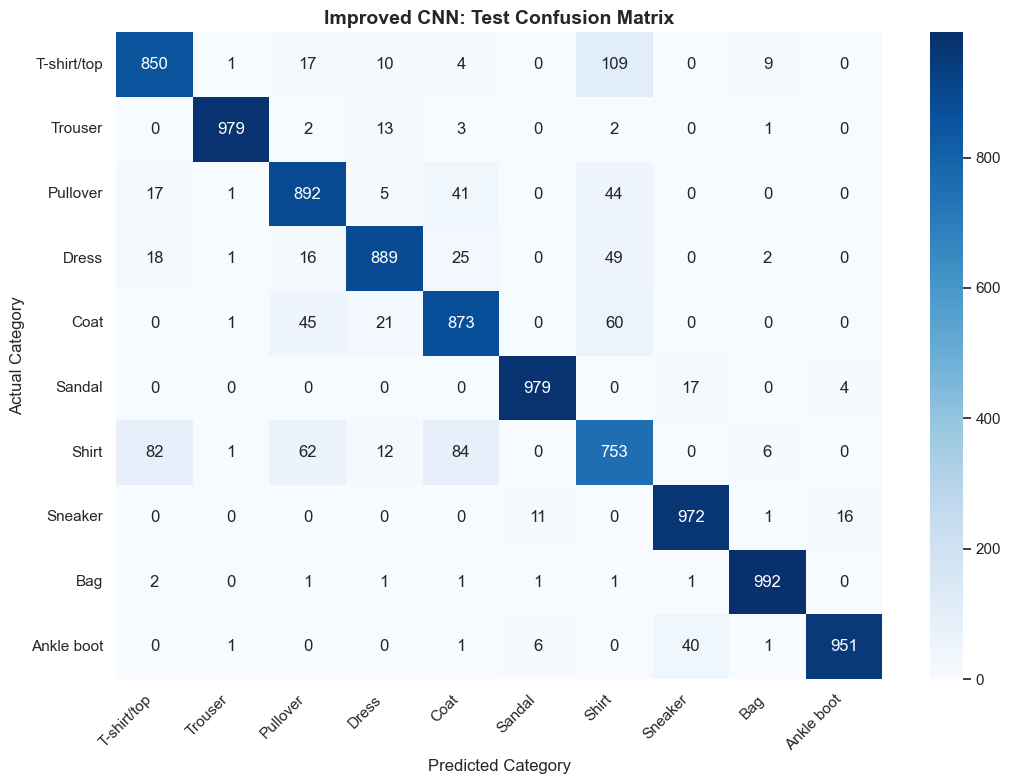

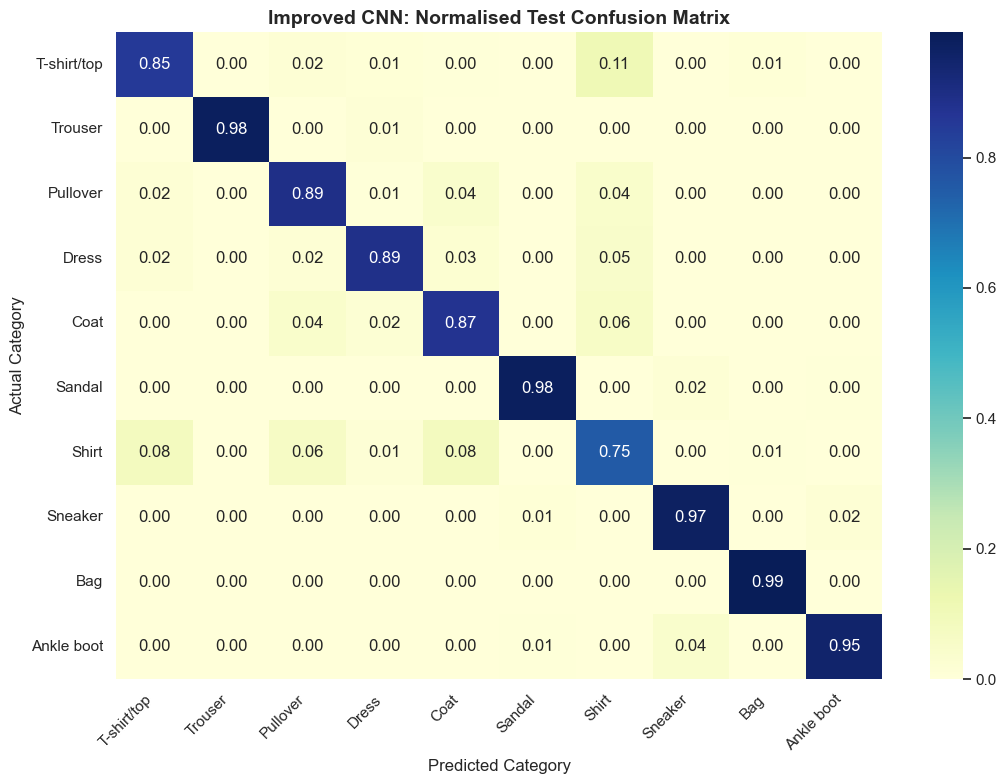


TOP 15 CLASSIFICATION ERROR PAIRS
----------------------------------------------------------------------
Actual Category Predicted Category  Number of Errors
    T-shirt/top              Shirt               109
          Shirt               Coat                84
          Shirt        T-shirt/top                82
          Shirt           Pullover                62
           Coat              Shirt                60
          Dress              Shirt                49
           Coat           Pullover                45
       Pullover              Shirt                44
       Pullover               Coat                41
     Ankle boot            Sneaker                40
          Dress               Coat                25
           Coat              Dress                21
          Dress        T-shirt/top                18
       Pullover        T-shirt/top                17
         Sandal            Sneaker                17


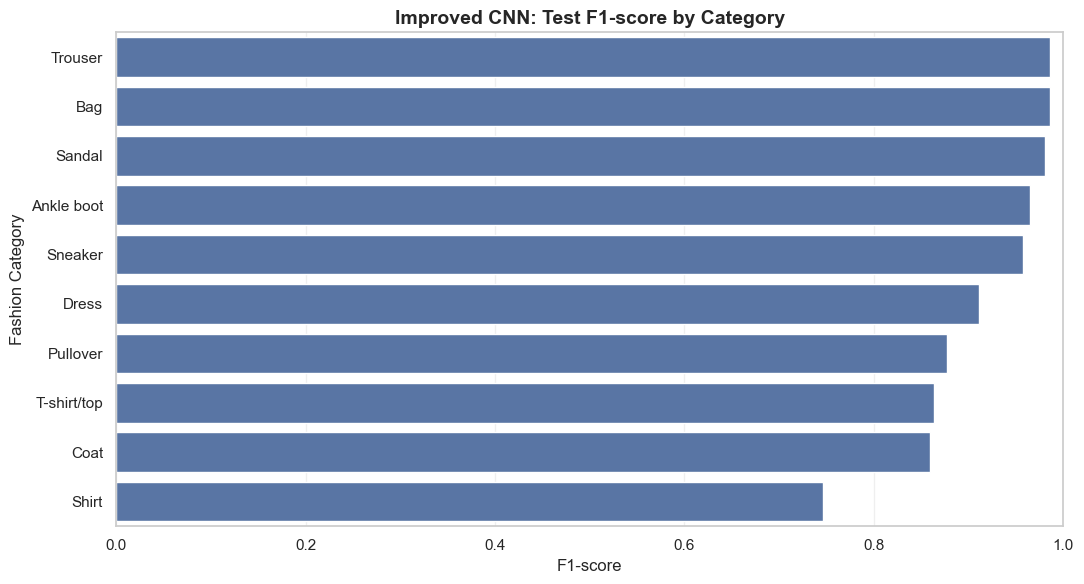


IMPROVED CNN TEST EVALUATION COMPLETED.


In [19]:
# STEP 18: FINAL TEST EVALUATION OF IMPROVED CNN

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ---------------------------------------------------------
# 1. GENERATE TEST PREDICTIONS
# ---------------------------------------------------------

print("=" * 70)
print("IMPROVED CNN: FINAL TEST EVALUATION")
print("=" * 70)

improved_test_loss, improved_test_accuracy = improved_cnn.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

improved_test_probabilities = improved_cnn.predict(
    X_test_cnn,
    verbose=0
)

improved_y_pred = np.argmax(
    improved_test_probabilities,
    axis=1
)

# ---------------------------------------------------------
# 2. CALCULATE OVERALL PERFORMANCE
# ---------------------------------------------------------

improved_precision = precision_score(
    y_test,
    improved_y_pred,
    average="macro"
)

improved_recall = recall_score(
    y_test,
    improved_y_pred,
    average="macro"
)

improved_f1 = f1_score(
    y_test,
    improved_y_pred,
    average="macro"
)

print("\nOVERALL TEST PERFORMANCE")
print("-" * 50)

print(f"Test loss: {improved_test_loss:.4f}")
print(f"Test accuracy: {improved_test_accuracy:.4f}")
print(f"Test precision (macro): {improved_precision:.4f}")
print(f"Test recall (macro): {improved_recall:.4f}")
print(f"Test F1-score (macro): {improved_f1:.4f}")

correct_predictions = np.sum(improved_y_pred == y_test)
incorrect_predictions = np.sum(improved_y_pred != y_test)

print(f"\nCorrect predictions: {correct_predictions:,}")
print(f"Incorrect predictions: {incorrect_predictions:,}")
print(f"Test error rate: {incorrect_predictions / len(y_test) * 100:.2f}%")

# ---------------------------------------------------------
# 3. DETAILED CLASSIFICATION REPORT
# ---------------------------------------------------------

print("\nDETAILED CLASSIFICATION REPORT")
print("-" * 70)

print(
    classification_report(
        y_test,
        improved_y_pred,
        target_names=class_names,
        digits=4
    )
)

# ---------------------------------------------------------
# 4. GENERATE CONFUSION MATRIX
# ---------------------------------------------------------

improved_cm = confusion_matrix(
    y_test,
    improved_y_pred
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    improved_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "Improved CNN: Test Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. NORMALISED CONFUSION MATRIX
# ---------------------------------------------------------

improved_cm_normalised = (
    improved_cm.astype("float")
    / improved_cm.sum(axis=1, keepdims=True)
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    improved_cm_normalised,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "Improved CNN: Normalised Test Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6. IDENTIFY THE MOST COMMON CLASSIFICATION ERRORS
# ---------------------------------------------------------

error_records = []

for actual in range(len(class_names)):
    for predicted in range(len(class_names)):

        if actual != predicted and improved_cm[actual, predicted] > 0:

            error_records.append({
                "Actual Category": class_names[actual],
                "Predicted Category": class_names[predicted],
                "Number of Errors": improved_cm[actual, predicted]
            })

error_table = pd.DataFrame(error_records)

error_table = error_table.sort_values(
    by="Number of Errors",
    ascending=False
)

print("\nTOP 15 CLASSIFICATION ERROR PAIRS")
print("-" * 70)

print(error_table.head(15).to_string(index=False))

# ---------------------------------------------------------
# 7. PER-CLASS F1-SCORE VISUALISATION
# ---------------------------------------------------------

class_report = classification_report(
    y_test,
    improved_y_pred,
    target_names=class_names,
    output_dict=True
)

class_f1 = pd.DataFrame({
    "Category": class_names,
    "F1-score": [
        class_report[name]["f1-score"]
        for name in class_names
    ]
})

class_f1 = class_f1.sort_values(
    by="F1-score",
    ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=class_f1,
    x="F1-score",
    y="Category"
)

plt.title(
    "Improved CNN: Test F1-score by Category",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("F1-score")
plt.ylabel("Fashion Category")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nIMPROVED CNN TEST EVALUATION COMPLETED.")

FINAL TEST PERFORMANCE COMPARISON
       Model  Accuracy  Precision  Recall  Macro F1  Incorrect Predictions
Baseline CNN    0.9128     0.9127  0.9128    0.9122                    872
Improved CNN    0.9130     0.9139  0.9130    0.9132                    870

MODEL COMPLEXITY AND TEST LOSS
---------------------------------------------------------------------------
       Model  Parameters  Test Loss
Baseline CNN      421642   0.254986
Improved CNN      156938   0.236847


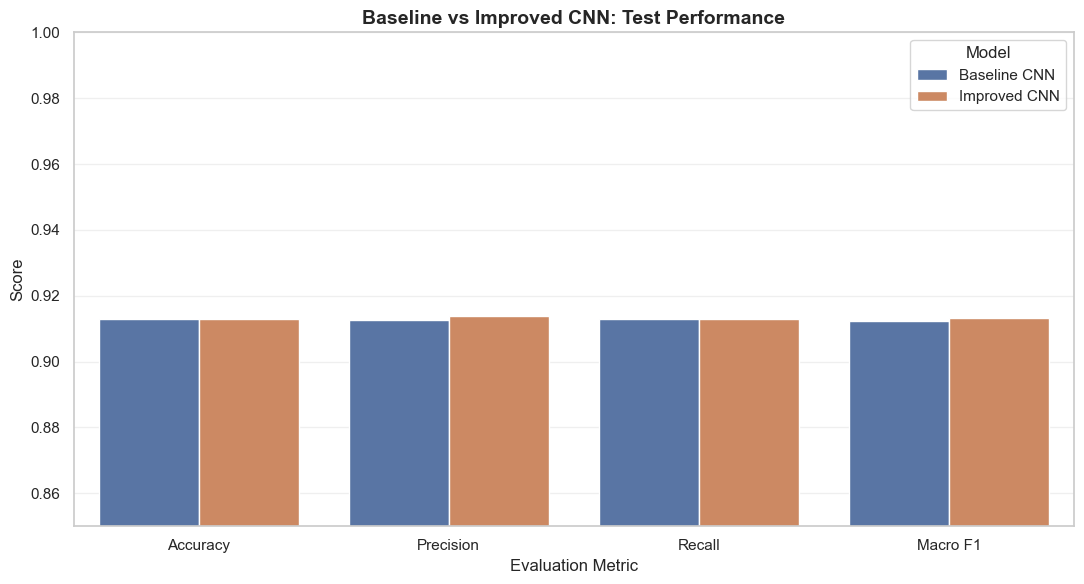


PER-CLASS F1-SCORE COMPARISON
---------------------------------------------------------------------------
   Category  Baseline CNN  Improved CNN
T-shirt/top        0.8655        0.8634
    Trouser        0.9884        0.9864
   Pullover        0.8637        0.8767
      Dress        0.9171        0.9113
       Coat        0.8657        0.8593
     Sandal        0.9783        0.9805
      Shirt        0.7378        0.7463
    Sneaker        0.9571        0.9576
        Bag        0.9824        0.9861
 Ankle boot        0.9660        0.9650


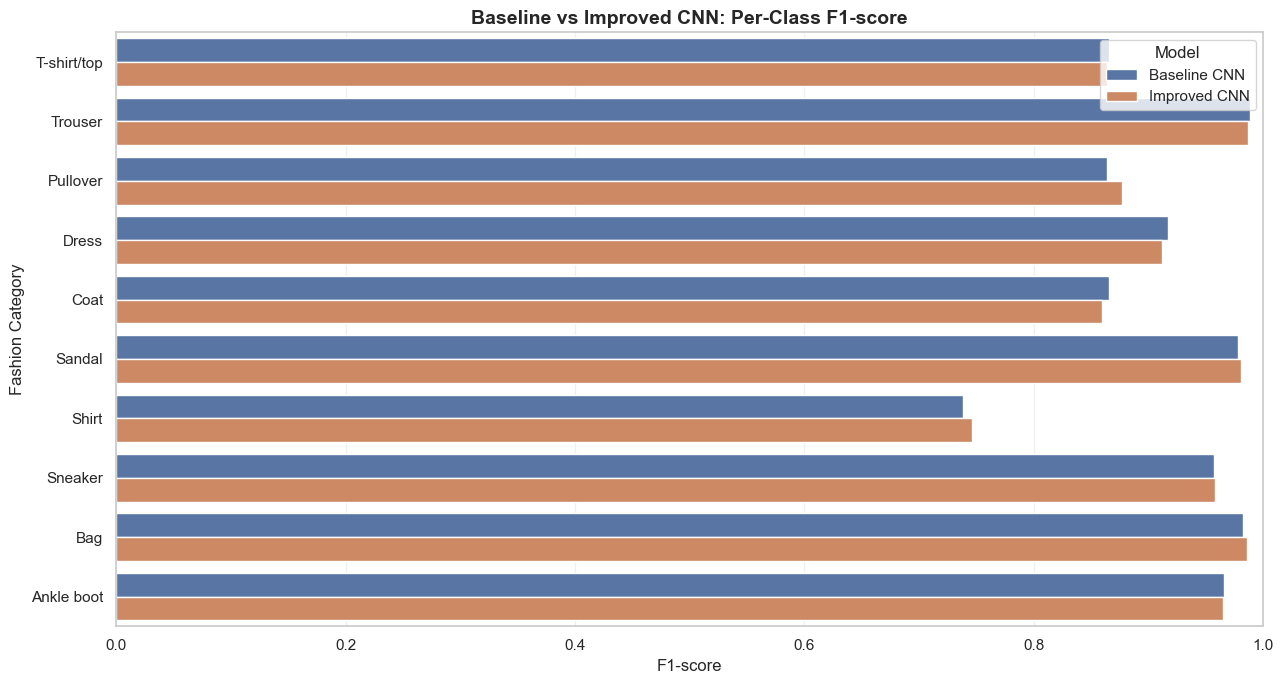


IMPROVEMENT ACHIEVED BY THE IMPROVED CNN
---------------------------------------------------------------------------
Accuracy: +0.0002 (+0.02 percentage points)
Precision: +0.0012 (+0.12 percentage points)
Recall: +0.0002 (+0.02 percentage points)
Macro F1: +0.0010 (+0.10 percentage points)

Parameter reduction: 62.78%

FINAL MODEL COMPARISON COMPLETED.


In [20]:
# STEP 19: BASELINE VS IMPROVED CNN COMPARISON

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ---------------------------------------------------------
# 1. OBTAIN BASELINE PREDICTIONS
# ---------------------------------------------------------

baseline_test_probabilities = baseline_cnn.predict(
    X_test_cnn,
    verbose=0
)

baseline_y_pred = np.argmax(
    baseline_test_probabilities,
    axis=1
)

# ---------------------------------------------------------
# 2. CALCULATE COMPARABLE TEST METRICS
# ---------------------------------------------------------

models = {
    "Baseline CNN": baseline_y_pred,
    "Improved CNN": improved_y_pred
}

comparison_results = []

for model_name, predictions in models.items():

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="macro"
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Incorrect Predictions": np.sum(predictions != y_test)
    })

comparison_df = pd.DataFrame(comparison_results)

print("=" * 75)
print("FINAL TEST PERFORMANCE COMPARISON")
print("=" * 75)

print(comparison_df.round(4).to_string(index=False))

# ---------------------------------------------------------
# 3. INCLUDE MODEL COMPLEXITY AND TEST LOSS
# ---------------------------------------------------------

complexity_df = pd.DataFrame({
    "Model": ["Baseline CNN", "Improved CNN"],
    "Parameters": [
        baseline_cnn.count_params(),
        improved_cnn.count_params()
    ],
    "Test Loss": [
        test_loss,
        improved_test_loss
    ]
})

print("\nMODEL COMPLEXITY AND TEST LOSS")
print("-" * 75)

print(complexity_df.to_string(index=False))

# ---------------------------------------------------------
# 4. VISUALISE OVERALL PERFORMANCE
# ---------------------------------------------------------

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1"
]

plot_df = comparison_df.melt(
    id_vars="Model",
    value_vars=metric_columns,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title(
    "Baseline vs Improved CNN: Test Performance",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0.85, 1.00)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. COMPARE PER-CLASS F1-SCORES
# ---------------------------------------------------------

baseline_report = classification_report(
    y_test,
    baseline_y_pred,
    target_names=class_names,
    output_dict=True
)

improved_report = classification_report(
    y_test,
    improved_y_pred,
    target_names=class_names,
    output_dict=True
)

per_class_comparison = pd.DataFrame({
    "Category": class_names,
    "Baseline CNN": [
        baseline_report[name]["f1-score"]
        for name in class_names
    ],
    "Improved CNN": [
        improved_report[name]["f1-score"]
        for name in class_names
    ]
})

print("\nPER-CLASS F1-SCORE COMPARISON")
print("-" * 75)

print(per_class_comparison.round(4).to_string(index=False))

per_class_plot = per_class_comparison.melt(
    id_vars="Category",
    var_name="Model",
    value_name="F1-score"
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=per_class_plot,
    x="F1-score",
    y="Category",
    hue="Model"
)

plt.title(
    "Baseline vs Improved CNN: Per-Class F1-score",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("F1-score")
plt.ylabel("Fashion Category")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6. CALCULATE THE DIFFERENCE BETWEEN MODELS
# ---------------------------------------------------------

print("\nIMPROVEMENT ACHIEVED BY THE IMPROVED CNN")
print("-" * 75)

for metric in metric_columns:

    baseline_value = comparison_df.loc[
        comparison_df["Model"] == "Baseline CNN", metric
    ].iloc[0]

    improved_value = comparison_df.loc[
        comparison_df["Model"] == "Improved CNN", metric
    ].iloc[0]

    difference = improved_value - baseline_value

    print(
        f"{metric}: {difference:+.4f} "
        f"({difference * 100:+.2f} percentage points)"
    )

parameter_reduction = (
    1 - improved_cnn.count_params() / baseline_cnn.count_params()
) * 100

print(f"\nParameter reduction: {parameter_reduction:.2f}%")

print("\nFINAL MODEL COMPARISON COMPLETED.")

CNN FEATURE EXTRACTION ANALYSIS
Test image index: 0
Actual category: Ankle boot
Predicted category: Ankle boot
Prediction confidence: 0.9993


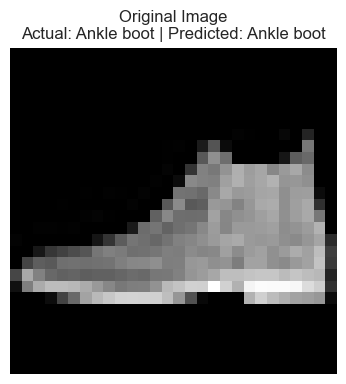

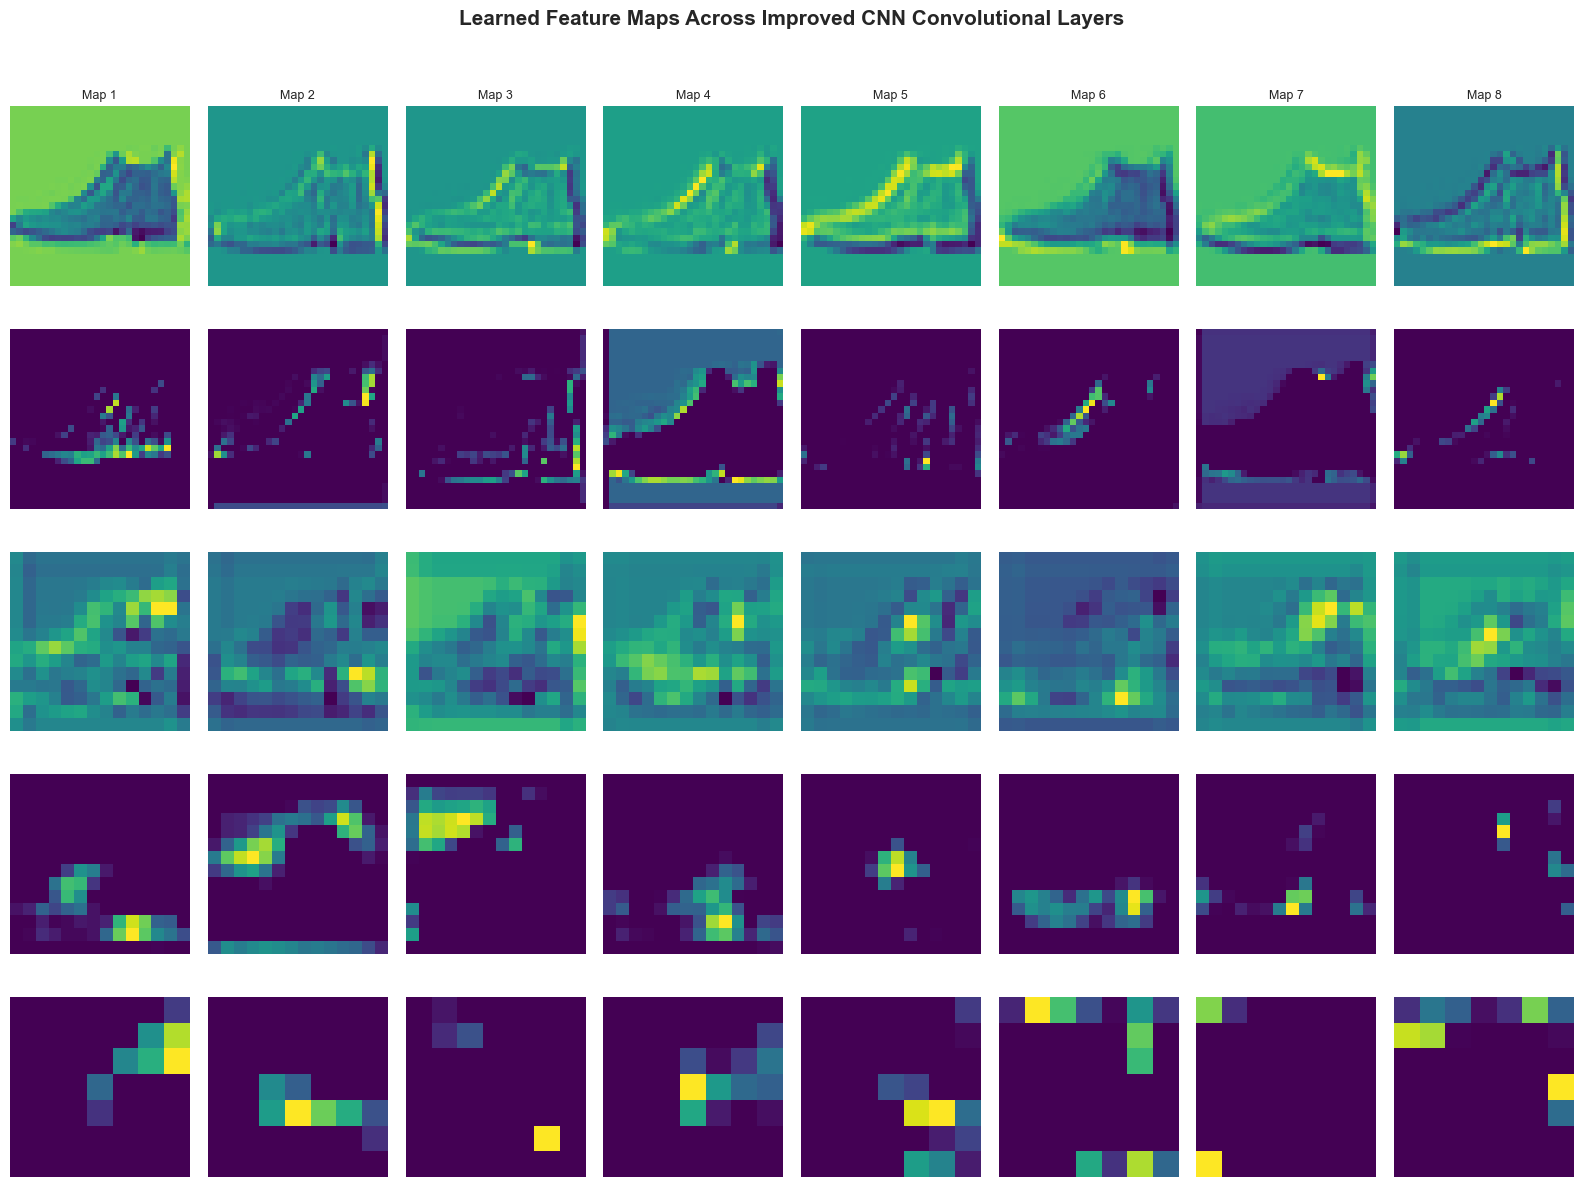


FEATURE EXTRACTION DIMENSIONS
-------------------------------------------------------
conv_1: (1, 28, 28, 32)
conv_2: (1, 28, 28, 32)
conv_3: (1, 14, 14, 64)
conv_4: (1, 14, 14, 64)
conv_5: (1, 7, 7, 128)

FEATURE MAP VISUALISATION COMPLETED.


In [22]:
# STEP 20 (CORRECTED): VISUALISE LEARNED CNN FEATURE MAPS

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# ---------------------------------------------------------
# 1. SELECT A CORRECTLY CLASSIFIED TEST IMAGE
# ---------------------------------------------------------

correct_indices = np.where(improved_y_pred == y_test)[0]

if len(correct_indices) == 0:
    raise ValueError("No correctly classified test images found.")

sample_index = correct_indices[0]
sample_image = X_test_cnn[sample_index:sample_index + 1]

actual_class = class_names[y_test[sample_index]]
predicted_class = class_names[improved_y_pred[sample_index]]

confidence = np.max(improved_test_probabilities[sample_index])

print("=" * 70)
print("CNN FEATURE EXTRACTION ANALYSIS")
print("=" * 70)

print(f"Test image index: {sample_index}")
print(f"Actual category: {actual_class}")
print(f"Predicted category: {predicted_class}")
print(f"Prediction confidence: {confidence:.4f}")

# ---------------------------------------------------------
# 2. CREATE A FUNCTIONAL FEATURE EXTRACTOR
# ---------------------------------------------------------

convolutional_layer_names = [
    "conv_1",
    "conv_2",
    "conv_3",
    "conv_4",
    "conv_5"
]

# Create a symbolic input matching the original model.
feature_input = tf.keras.Input(shape=(28, 28, 1))

# Pass it through the existing trained model layers.
x = feature_input
feature_outputs = []

for layer in improved_cnn.layers:

    x = layer(x)

    if layer.name in convolutional_layer_names:
        feature_outputs.append(x)

feature_extractor = tf.keras.Model(
    inputs=feature_input,
    outputs=feature_outputs
)

# Extract feature maps using inference mode.
feature_maps = feature_extractor(
    sample_image,
    training=False
)

# ---------------------------------------------------------
# 3. DISPLAY ORIGINAL TEST IMAGE
# ---------------------------------------------------------

plt.figure(figsize=(4, 4))

plt.imshow(
    sample_image[0].squeeze(),
    cmap="gray"
)

plt.title(
    f"Original Image\nActual: {actual_class} | Predicted: {predicted_class}"
)

plt.axis("off")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 4. VISUALISE FEATURE MAPS
# ---------------------------------------------------------

number_of_maps = 8

fig, axes = plt.subplots(
    len(feature_maps),
    number_of_maps,
    figsize=(16, 12)
)

for layer_index, layer_features in enumerate(feature_maps):

    maps = layer_features[0].numpy()

    for map_index in range(number_of_maps):

        axes[layer_index, map_index].imshow(
            maps[:, :, map_index],
            cmap="viridis"
        )

        axes[layer_index, map_index].axis("off")

        if layer_index == 0:
            axes[layer_index, map_index].set_title(
                f"Map {map_index + 1}",
                fontsize=9
            )

    axes[layer_index, 0].set_ylabel(
        convolutional_layer_names[layer_index],
        fontsize=11,
        fontweight="bold",
        rotation=0,
        labelpad=65
    )

plt.suptitle(
    "Learned Feature Maps Across Improved CNN Convolutional Layers",
    fontsize=15,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. DISPLAY FEATURE MAP DIMENSIONS
# ---------------------------------------------------------

print("\nFEATURE EXTRACTION DIMENSIONS")
print("-" * 55)

for name, output in zip(
    convolutional_layer_names,
    feature_maps
):
    print(f"{name}: {tuple(output.shape)}")

print("\nFEATURE MAP VISUALISATION COMPLETED.")